# Q2E | Train Polynomial Regression

# Imports

In [1]:
from itertools import product

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from Q2.consts import *

from utils import read_csv_to_df
from utils.scoring.standard_error import standard_error

from Q2.utils import (
	chronological_split,
	Q2_CROSS_VALIDATION,
	Q2_PLOTTING,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

## Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


The same chronological split as Q2B, Q2C and Q2D. `test_df` is not used again in this notebook.

## Attributes

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]
CATEGORICAL = BINARY + MULTI_LEVEL

ATTRIBUTES = CONTINUOUS + CATEGORICAL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"continuous: {', '.join(CONTINUOUS)}")
print(f"categorical: {', '.join(CATEGORICAL)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
continuous: Temp, FeelsLike, Humidity, Wind
categorical: Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


The same 11 attributes as Q2D: 4 continuous, 3 binary and 4 multi-level codes. `CATEGORICAL` holds the 7 binary and multi-level attributes together. `ID`, `Date`, `Casual` and `Registered` are left out, as concluded in Q2B.

## Folds

In [5]:
FOLDS = Q2_CROSS_VALIDATION.make_time_folds(
	data=train_df,
	date_col="Date",
	n_splits=CV_SPLITS,
	test_size=CV_TEST_SIZE
)
# mean validation rows / training rows of the folds, used by every SE below
TEST_TRAIN_RATIO = Q2_CROSS_VALIDATION.test_train_ratio(folds=FOLDS)
print(len(FOLDS))

pd.DataFrame({
	"train rows": [len(train_index) for train_index, _ in FOLDS],
	"validation rows": [len(val_index) for _, val_index in FOLDS],
	"validation first date": [f"{train_df.loc[val_index, 'Date'].min():%Y-%m-%d}" for _, val_index in FOLDS],
	"validation last date": [f"{train_df.loc[val_index, 'Date'].max():%Y-%m-%d}" for _, val_index in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

6


,train rows,validation rows,validation first date,validation last date
fold,,,,
1,398,31,2012-02-03,2012-03-04
2,429,31,2012-03-05,2012-04-04
3,460,31,2012-04-05,2012-05-05
4,491,31,2012-05-06,2012-06-05
5,522,31,2012-06-06,2012-07-06
6,553,31,2012-07-07,2012-08-06


# Method
**Polynomial regression.** Polynomial regression is linear regression fit on extra columns. `PolynomialFeatures(degree)` takes the 4 continuous attributes (`Temp`, `FeelsLike`, `Humidity`, `Wind`) and adds every product of up to `degree` of them. At degree 2 that is each of the four squared and each pair of them multiplied together. The 7 categorical attributes (`Year`, `IsHoliday`, `IsWorkday`, `Season`, `Month`, `Weekday`, `Weather`) get no polynomial terms: they go into the model as they are, next to the polynomial columns. Q1E put every one of its columns through `PolynomialFeatures`, and the Why Not All 11 Attributes section tests that here. The model fit on the columns is the same as in Q2D: closed form `LinearRegression` first, then `SGDRegressor` with no penalty, Ridge, Lasso and Elastic Net. Degree 1 adds no columns, so it is Q2D's closed form model on the 11 raw attributes. Q2E starts again from the 11 raw attributes: the polynomial terms take the place of the hand-made shapes from Q2D.

**Pipeline.** Every model uses the same steps, built by `poly_pipeline` below. A `ColumnTransformer` sends the 4 continuous attributes through `StandardScaler` and `PolynomialFeatures` and passes the 7 categorical attributes through unchanged. A second `StandardScaler` then puts all the columns on one scale, and the model comes last. The first scaler centers each continuous attribute before it is squared or multiplied. The SGD section tests the pipeline without the first scaler. The target is left in its own units.

**Cross-validation.** Every model is scored on the same 6 time-ordered folds as Q2D. Each fold trains on every training day before its validation block and validates on the next 31 days. The first validation block starts on 2012-02-03, so every fold has days of 2012 to train on. Q2D gives the reasons for these folds and their two limits: 6 folds make the 1 SE rule coarse, and each fold looks at most 31 days ahead while the test set covers 147 days. The folds are built once (`FOLDS`) and reused by every experiment, so every model is validated on exactly the same days and any two models can be compared fold by fold. Q1E tested imputing its missing rows. This dataset has no missing values, so there is no Missing Rows section here.

**Metric.** The metric is RMSE (root mean squared error), reported for the validation rows and for the training rows of each fold. It is in the same units as Rentals (rentals per day), it penalizes large misses more than small ones, and it matches the squared error that linear regression minimizes.

**Noise rule.** A lower mean RMSE is not automatically a real improvement, because the score moves from fold to fold. Each experiment is compared with a baseline through the 6 per-fold differences in validation RMSE (experiment minus baseline). SE is the standard error of the mean of those differences, corrected for the folds sharing most of their training rows. The correction uses the folds' mean ratio of validation rows to training rows (`TEST_TRAIN_RATIO`). The rule used throughout:

- **really better:** the mean change is below -1 SE.
- **really worse:** the mean change is above +1 SE.
- **noise:** anything in between. The simpler model is kept.

**Charts.** Each experiment has one chart. Left: RMSE on every fold, dots for validation and x marks for training, with the means in the legend. Right: the per-fold change in validation RMSE against the baseline (green is better, red is worse), the mean change as a dashed line, and the ±1 SE noise band in gray. The folds run left to right in time order, and each one is labelled with the first date of its validation block. The title gives the verdict.

In [6]:
def poly_pipeline(*, degree, model, first_scaler=True):
	"""Polynomial columns of the continuous attributes, the categorical attributes as they are, then the model.

	Args:
		degree: Degree of PolynomialFeatures.
		model: Estimator fit on the columns (LinearRegression or SGDRegressor).
		first_scaler: False leaves out the StandardScaler in front of PolynomialFeatures.

	Returns:
		An unfitted pipeline that takes the 11 raw attributes.
	"""
	# the polynomial branch: scale the continuous attributes, then square and multiply them
	poly_steps = [PolynomialFeatures(degree=degree, include_bias=False)]
	if first_scaler:
		poly_steps.insert(0, StandardScaler())

	return make_pipeline(
		# the continuous attributes go through the polynomial branch. remainder="passthrough" keeps the
		# categorical attributes as they are, after the polynomial columns
		ColumnTransformer([("poly", make_pipeline(*poly_steps), CONTINUOUS)], remainder="passthrough"),
		# all the columns on one scale
		StandardScaler(),
		model,
	)

# Closed Form by Degree
This section changes one thing, the degree, and fits every degree with closed form `LinearRegression`: one direct solve, with no learning rate and no penalty to tune. scikit-learn computes that solution with an SVD-based solver. Each degree is charted against the degree below it.

## Closed Form by Degree > Degree 1
The baseline. Degree 1 adds no columns, so this is Q2D's closed form model on the 11 raw attributes (validation RMSE 1071.3037 there).

In [7]:
degree_scores = {}
degree_scores[1] = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=poly_pipeline(degree=1, model=LinearRegression()),
	folds=FOLDS,
	target=TARGET
)

degree1_val_scores, degree1_train_scores = degree_scores[1]
print(f"val RMSE {degree1_val_scores.mean():.4f} | train RMSE {degree1_train_scores.mean():.4f}")

val RMSE 1071.3037 | train RMSE 716.3116


## Closed Form by Degree > Degree 2
Degree 2 adds each continuous attribute squared and each pair of continuous attributes multiplied together.

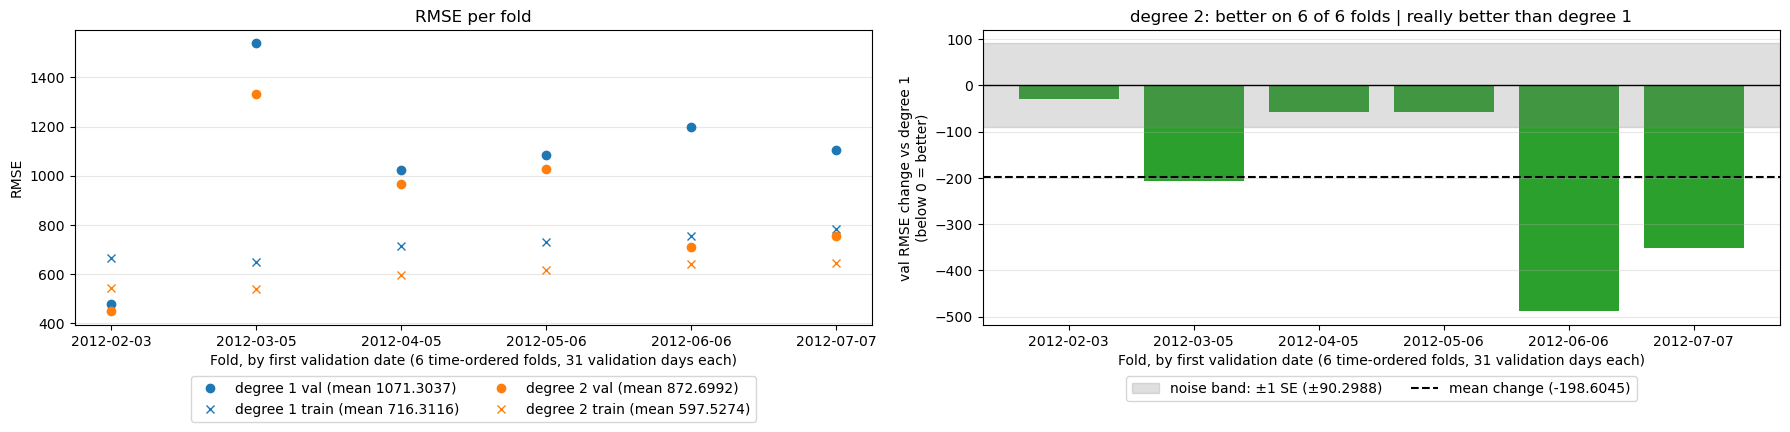

In [8]:
degree_scores[2] = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=poly_pipeline(degree=2, model=LinearRegression()),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=degree_scores[1],
	compare=degree_scores[2],
	baseline_name="degree 1",
	compare_name="degree 2",
	folds=FOLDS,
	dates=train_df["Date"],
)

## Closed Form by Degree > Degrees 3 and 4
Each is compared with the degree below it.

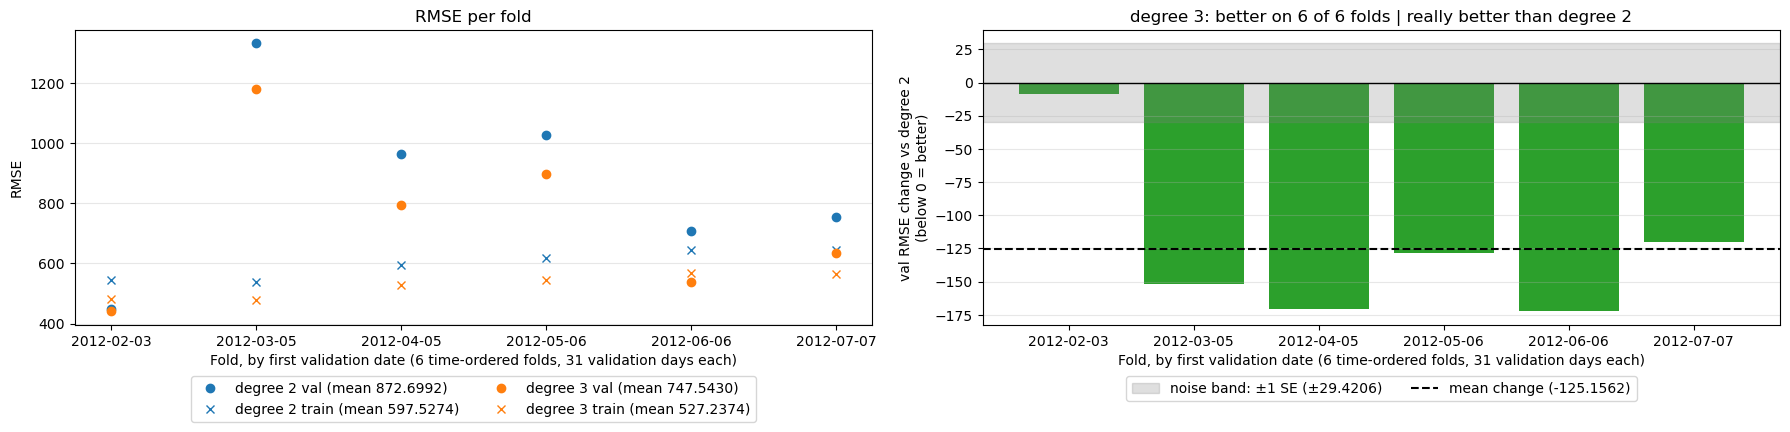

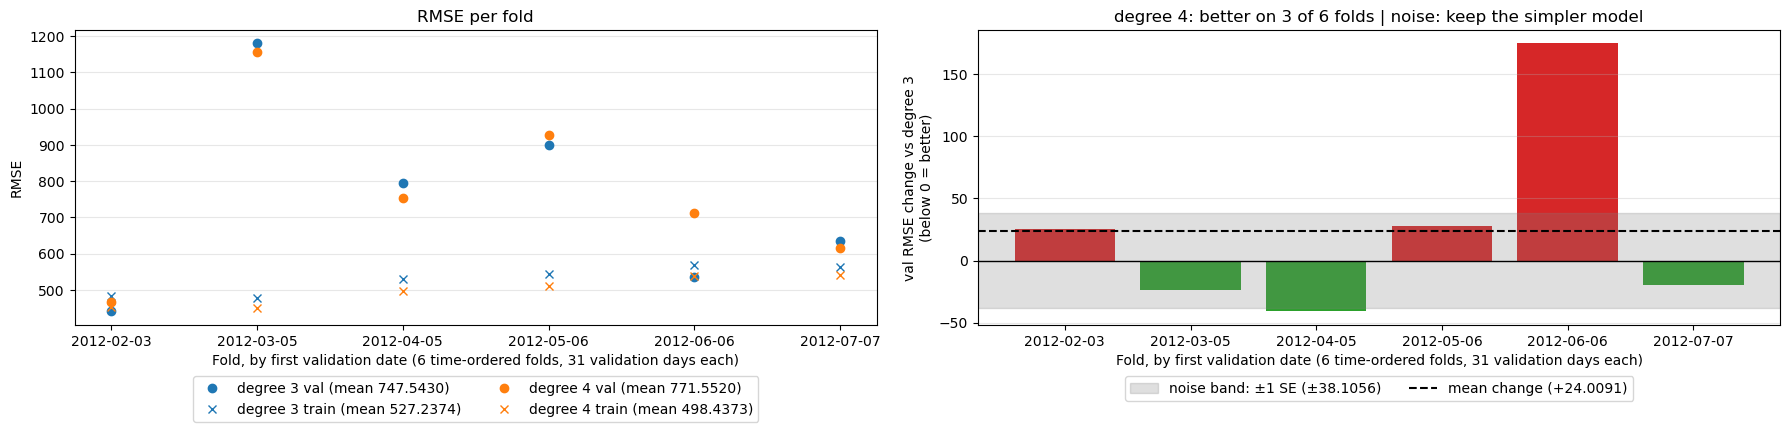

In [9]:
for degree in [3, 4]:
	degree_scores[degree] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=degree, model=LinearRegression()),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=degree_scores[degree - 1],
		compare=degree_scores[degree],
		baseline_name=f"degree {degree - 1}",
		compare_name=f"degree {degree}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Degree Summary

In [10]:
degree_summary = pd.DataFrame({
	f"degree {degree}": {
		# the polynomial columns PolynomialFeatures makes from the 4 continuous attributes, plus the 7 categorical attributes
		"columns": PolynomialFeatures(degree=degree, include_bias=False).fit(train_df[CONTINUOUS]).n_output_features_ + len(CATEGORICAL),
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs degree 1": (val - degree1_val_scores).mean(),
		"SE": standard_error(diff=val - degree1_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < degree1_val_scores),
		# the same comparison against the degree below (degree 1 is compared with itself)
		"change vs previous degree": (val - degree_scores[max(degree - 1, 1)][0]).mean(),
		"SE (previous degree)": standard_error(diff=val - degree_scores[max(degree - 1, 1)][0], test_train_ratio=TEST_TRAIN_RATIO),
		"folds better (previous degree)": np.sum(val < degree_scores[max(degree - 1, 1)][0]),
	}
	for degree, (val, train) in degree_scores.items()
}).T
int_columns = ["columns", "folds better", "folds better (previous degree)"]
degree_summary[int_columns] = degree_summary[int_columns].astype(int)
degree_summary.round(4)

,columns,val RMSE,train RMSE,change vs degree 1,SE,folds better,change vs previous degree,SE (previous degree),folds better (previous degree)
degree 1,11,1071.3037,716.3116,0.0000,0.0000,0,0.0000,0.0000,0
degree 2,21,872.6992,597.5274,-198.6045,90.2988,6,-198.6045,90.2988,6
degree 3,41,747.5430,527.2374,-323.7607,106.9619,6,-125.1562,29.4206,6
degree 4,76,771.5520,498.4373,-299.7516,91.7736,6,24.0091,38.1056,3


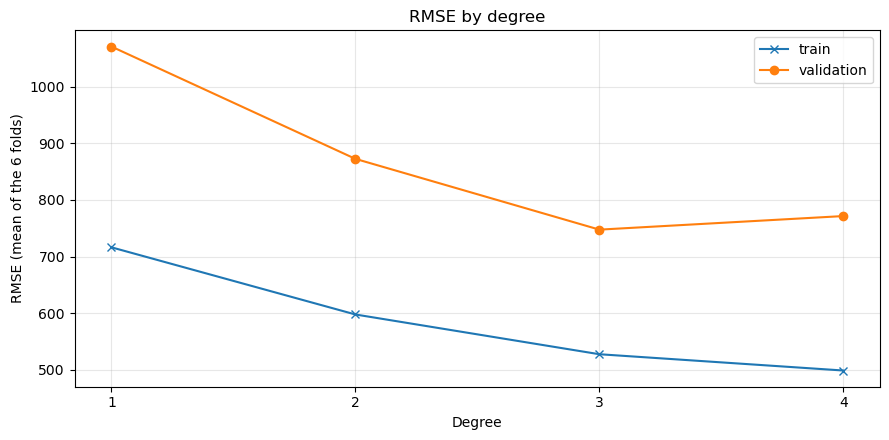

In [11]:
degrees = list(degree_scores)
val_means = [degree_scores[degree][0].mean() for degree in degrees]
train_means = [degree_scores[degree][1].mean() for degree in degrees]

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(degrees, train_means, "x-", color="C0", label="train")
ax.plot(degrees, val_means, "o-", color="C1", label="validation")
ax.set_xticks(degrees)
ax.set_xlabel("Degree")
ax.set_ylabel("RMSE (mean of the 6 folds)")
ax.set_title("RMSE by degree")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

**Impact of the degree.** Two steps up are real improvements and the third is not. Degree 2 lowers validation RMSE from 1071.3037 at degree 1 to 872.6992 (-198.6045, SE 90.2988) and is better on all 6 folds. Degree 3 lowers it again to 747.5430. Against degree 2 that is a change of -125.1562 (SE 29.4206), also better on all 6 folds. Degree 4 scores 771.5520. Against degree 3 that is a change of +24.0091, inside its SE of 38.1056, and it is better on only 3 of 6 folds, so the verdict is noise and the simpler degree 3 is kept. Against degree 1, degrees 3 and 4 are both really better (-323.7607 and -299.7516). The number of columns roughly doubles at each step (11, 21, 41, 76), and the last doubling buys nothing. Degree 3 is the selected degree.

**Underfitting and overfitting.** Training RMSE falls at every degree: 716.3116, 597.5274, 527.2374, 498.4373. Validation RMSE falls with it up to degree 3 and then turns back up: 1071.3037, 872.6992, 747.5430, 771.5520. Degrees 1 and 2 underfit: both their training and their validation RMSE are higher than at degree 3, so the extra columns were still adding signal. Degree 4 shows the first sign of overfitting: it fits the training rows better than degree 3 while the validation RMSE gets worse, although that rise is within noise. At every degree the validation RMSE is far above the training RMSE (ex 747.5430 against 527.2374 at degree 3). That gap is there at degree 1 too, so it is not caused by the polynomial columns.

## Selected Degree
The degree every section below uses. The rule: start at degree 1 and step up one degree at a time while the next degree is really better than the current one (mean change below -1 SE). Stop at the first step that is not. The degree is typed by hand from the Degree Summary.

In [12]:
# Typed by hand from the Degree Summary ("change vs previous degree" against "SE (previous degree)"):
# the last degree that is really better than the degree below it, stepping up from degree 1.
BEST_DEGREE = 3

# Why Not All 11 Attributes
Q1E put every one of its columns through `PolynomialFeatures`. Here only the 4 continuous attributes go through it. This section tests the other choice: closed form `LinearRegression` at degree 2 with all 11 attributes through `StandardScaler`, `PolynomialFeatures`, `StandardScaler`. It is compared with the continuous-only degree 2 run above on the same 6 folds.

The comparison is a table with one row per fold, not the usual fold chart. The numbers are shown with 5 significant digits, so that a very large value stays readable.

In [13]:
# all 11 attributes through the polynomial step, as Q1E did with its columns
ALL_POLY = make_pipeline(
	StandardScaler(),
	PolynomialFeatures(degree=2, include_bias=False),
	StandardScaler(),
	LinearRegression(),
)
all_poly_val_scores, all_poly_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=ALL_POLY,
	folds=FOLDS,
	target=TARGET
)

continuous_val_scores, continuous_train_scores = degree_scores[2]
print(f"columns: continuous only {degree_summary.loc['degree 2', 'columns']} | all 11 {PolynomialFeatures(degree=2, include_bias=False).fit(train_df[ATTRIBUTES]).n_output_features_}")

all_poly_table = pd.DataFrame({
	"continuous only val RMSE": continuous_val_scores,
	"continuous only train RMSE": continuous_train_scores,
	"all 11 val RMSE": all_poly_val_scores,
	"all 11 train RMSE": all_poly_train_scores,
}, index=pd.Index([f"{train_df.loc[val_index, 'Date'].min():%Y-%m-%d}" for _, val_index in FOLDS], name="fold (first validation date)"))
all_poly_table.loc["mean"] = all_poly_table.mean()
# 5 significant digits, so a very large value stays readable
all_poly_table.map("{:.5g}".format)

columns: continuous only 21 | all 11 77


,continuous only val RMSE,continuous only train RMSE,all 11 val RMSE,all 11 train RMSE
fold (first validation date),,,,
2012-02-03,449.08,545.5,718.17,451.73
2012-03-05,1331.2,538.19,1.7742e+14,450.71
2012-04-05,965.08,595.91,925.51,483.95
2012-05-06,1027,616.44,931.57,497.29
2012-06-06,709.11,643.48,1182,519.76
2012-07-07,754.73,645.64,963.61,533.06
mean,872.7,597.53,2.957e+13,489.42


## Why Not All 11 Attributes > Worst Fold
A closer look at the fold where the all-11 run has its highest validation RMSE. The all-11 model is fit again on that fold's training rows, and three things are shown:

- **Columns and rank.** The number of polynomial columns, and the rank of those columns on the training rows. A rank below the number of columns means that some columns are exact combinations of other columns on those rows.
- **Largest coefficients.** The 10 coefficients with the largest absolute value, each next to the largest absolute value its column takes on the validation rows (after both scalers, so in standard deviations of the training rows).
- **Rows by `Year` and `Season`.** The row counts of the training rows and of the validation rows, and the number of validation rows whose prediction misses by more than 1e6.

In [14]:
# the fold where the all-11 run is worst
worst = int(np.argmax(all_poly_val_scores))
train_index, val_index = FOLDS[worst]
worst_train_df, worst_val_df = train_df.loc[train_index], train_df.loc[val_index]

worst_model = clone(ALL_POLY).fit(worst_train_df[ATTRIBUTES], worst_train_df[TARGET])
names = worst_model[1].get_feature_names_out(ATTRIBUTES)
# the polynomial columns after both scalers, as the model sees them
worst_train_columns = worst_model[:-1].transform(worst_train_df[ATTRIBUTES])
worst_val_columns = worst_model[:-1].transform(worst_val_df[ATTRIBUTES])
print(f"fold {worst + 1}: {len(names)} columns | rank on the training rows: {np.linalg.matrix_rank(worst_train_columns)}")

display(pd.DataFrame({
	"coefficient": worst_model[-1].coef_,
	"largest value on validation rows": np.abs(worst_val_columns).max(axis=0),
}, index=names).sort_values("coefficient", key=np.abs, ascending=False).head(10).map("{:.5g}".format))

worst_error = worst_val_df[TARGET] - worst_model.predict(worst_val_df[ATTRIBUTES])
pd.concat({
	"training rows": pd.crosstab(worst_train_df["Year"], worst_train_df["Season"]),
	"validation rows": pd.crosstab(worst_val_df["Year"], worst_val_df["Season"]),
	"validation rows missed by more than 1e6": pd.crosstab(worst_val_df["Year"], worst_val_df["Season"], values=worst_error.abs() > 1e6, aggfunc="sum"),
}).fillna(0).astype(int)

fold 2: 77 columns | rank on the training rows: 72


,coefficient,largest value on validation rows
Year Season,-1.0318e+14,2.2115
Year,-7.972e+13,2.3881
Season,-4.392e+13,1.1047
Year^2,-3.6145e+13,2.3881
IsHoliday IsWorkday,-7.1303e+12,0.36233
IsHoliday^2,-6.1145e+12,0.17678
IsWorkday^2,4.5625e+12,1.4599
IsWorkday,3.6777e+12,1.4599
IsHoliday,-1.1928e+12,0.17678
Temp FeelsLike,5824.8,1.0473


Season                                         1   2   3   4
                                        Year                
training rows                           0     90  92  94  89
                                        1     64   0   0   0
validation rows                         1     16  15   0   0
validation rows missed by more than 1e6 1      0  15   0   0

**Why the all-11 run fails.** With all 11 attributes through `PolynomialFeatures`, one fold fails completely. On the fold that starts on 2012-03-05 the validation RMSE is 1.7742e+14, while the training RMSE on that same fold is 450.71, lower than the continuous-only run's 538.19. The other five folds are ordinary (718.17 to 1182), and on two of them the all-11 run is even ahead (925.51 against 965.08, and 931.57 against 1027). One failed fold is enough to make the mean useless (2.957e+13).

The worst fold shows why:

- **Some columns are exact repeats on the training rows.** The 77 polynomial columns have rank 72 there, so 5 of them are exact combinations of the others. Closed form does not remove them. It gives them enormous coefficients that offset each other (-1.0318e+14 for `Year Season`, -7.972e+13 for `Year`, -4.392e+13 for `Season`), and on the training rows they cancel.
- **The inputs are not extreme.** The largest value these columns take on the validation rows is about 2.4 standard deviations, so the failure does not come from unusual values.
- **A new combination appears in the validation days.** In the training rows every `Year` 1 row is in `Season` 1 (64 rows, and none in seasons 2 to 4). There, `Year` times `Season` says nothing that `Year` and `Season` do not already say, which is what makes it an exact repeat. The validation block has 15 `Year` 1 rows in `Season` 2. The offsetting coefficients stop cancelling on exactly those rows: all 15 are missed by more than 1e6, and none of the 16 `Season` 1 rows is.
- **The other repeats are harmless.** A 0 / 1 column squared (`Year^2`, `IsHoliday^2`, `IsWorkday^2`) is the same column again on every row, training or validation, so its coefficients always cancel.

So products of the category codes can be exact repeats inside an early time-ordered fold and then break on the first day that brings a new combination, which is what the days after a training period do. The size of the failure (1e14) comes from offsetting coefficients, so the exact figure means nothing. This is why only the 4 continuous attributes get polynomial terms.

# Stochastic Gradient Descent (SGD)
Every model from here on uses degree `BEST_DEGREE`, with polynomial terms for the 4 continuous attributes only. Plain SGD (no penalty) is first compared with closed form at the same degree. Every penalty and learning rate experiment is then compared with plain SGD.

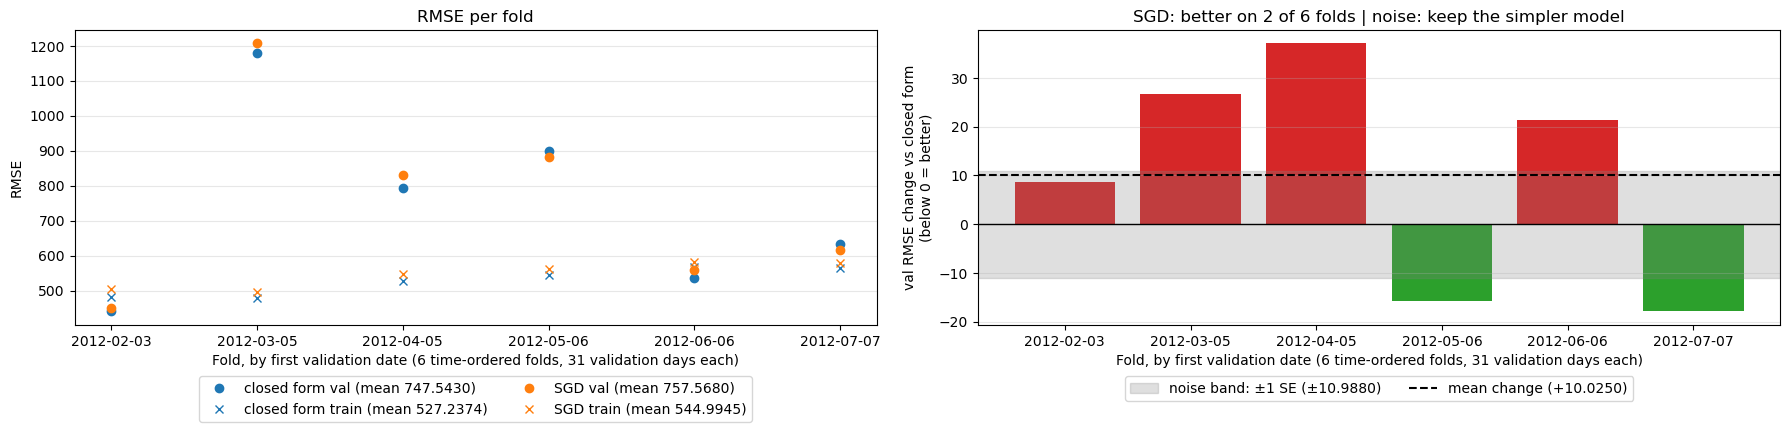

In [15]:
sgd_val_scores, sgd_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty=None, random_state=42)),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=degree_scores[BEST_DEGREE],
	compare=(sgd_val_scores, sgd_train_scores),
	baseline_name="closed form",
	compare_name="SGD",
	folds=FOLDS,
	dates=train_df["Date"],
)

**SGD against closed form.** At degree 3, plain SGD (no penalty) scores a validation RMSE of 757.5680 against 747.5430 for closed form. The change of +10.0250 is inside the ±10.9880 noise band and SGD is better on 2 of 6 folds, so the two are a tie. On the training rows SGD stops short of closed form (544.9945 against 527.2374). Plain SGD is the baseline for every experiment below.

## Without the First Scaler
The same plain SGD with the first `StandardScaler` removed, so `PolynomialFeatures` squares and multiplies the continuous attributes as they are. Compared with plain SGD above.

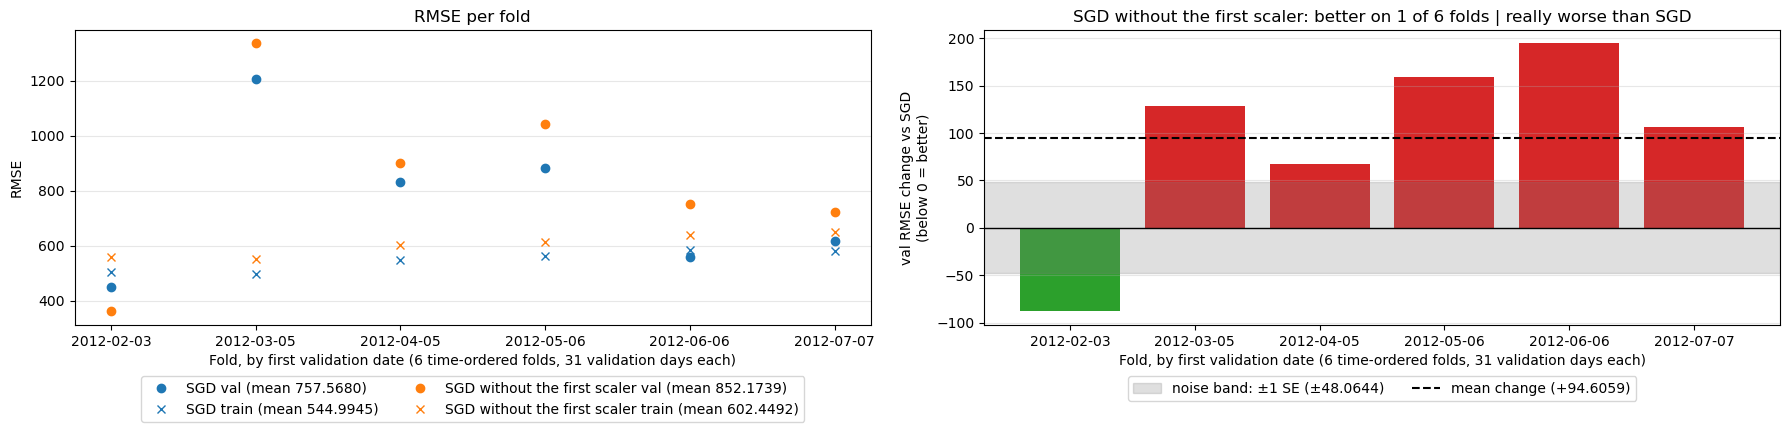

In [16]:
one_scaler_val_scores, one_scaler_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty=None, random_state=42), first_scaler=False),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=(sgd_val_scores, sgd_train_scores),
	compare=(one_scaler_val_scores, one_scaler_train_scores),
	baseline_name="SGD",
	compare_name="SGD without the first scaler",
	folds=FOLDS,
	dates=train_df["Date"],
)

**Impact of the first scaler.** Without the first scaler, plain SGD is really worse: 852.1739 against 757.5680 (+94.6059, SE 48.0644, better on 1 of 6 folds). Its training RMSE is worse too (602.4492 against 544.9945), so this is a poorer fit, not overfitting. Both runs use degree 3 and the same model settings. Only the scaling before `PolynomialFeatures` differs. With the first scaler SGD ties closed form (757.5680 against 747.5430), and without it SGD falls well behind. Centering the continuous attributes before they are squared and multiplied makes the polynomial columns less alike, and SGD needs that to get close to the least squares solution. The first scaler stays in every pipeline.

## Lasso

In [17]:
lasso_scores = {}

### Lasso > Penalty

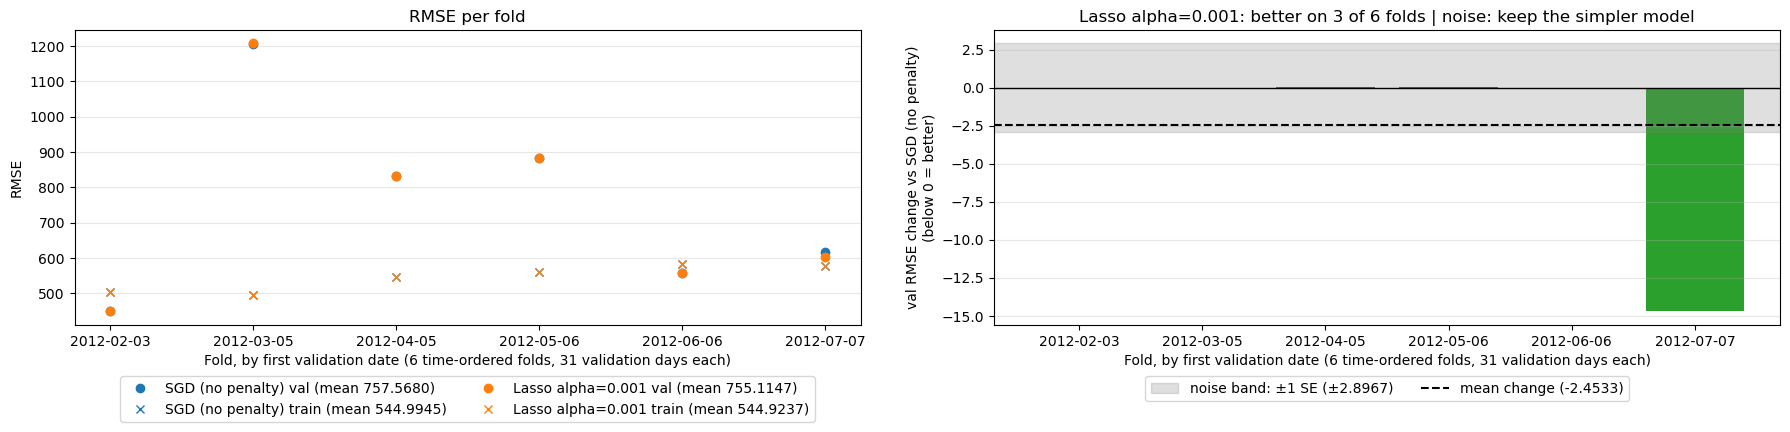

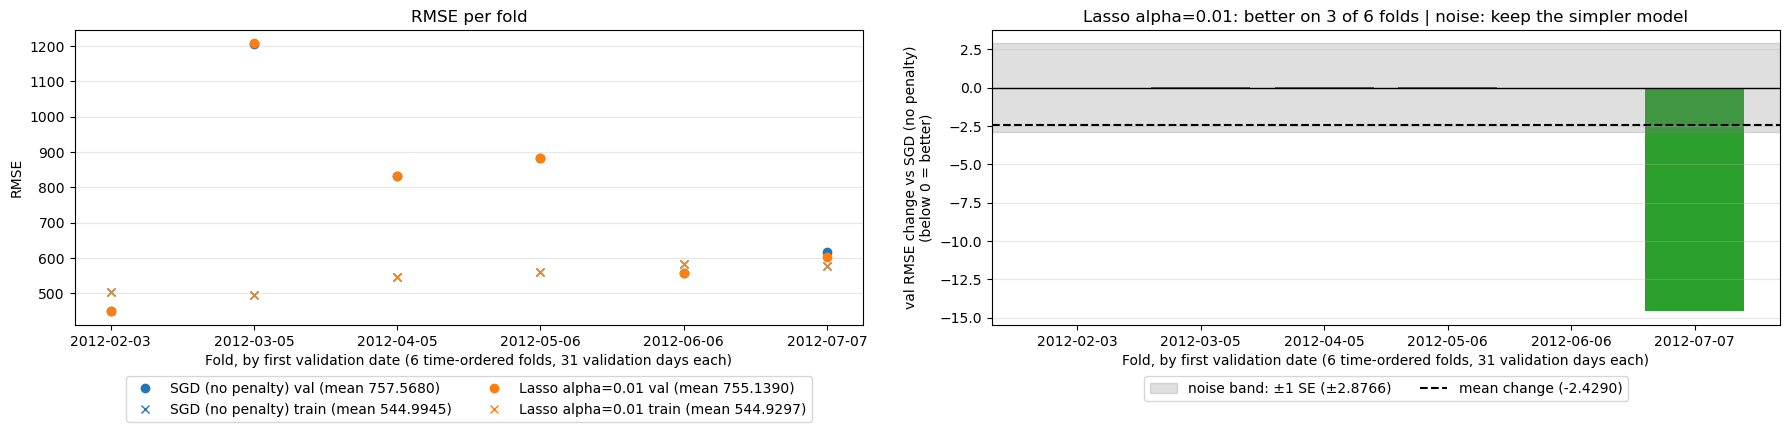

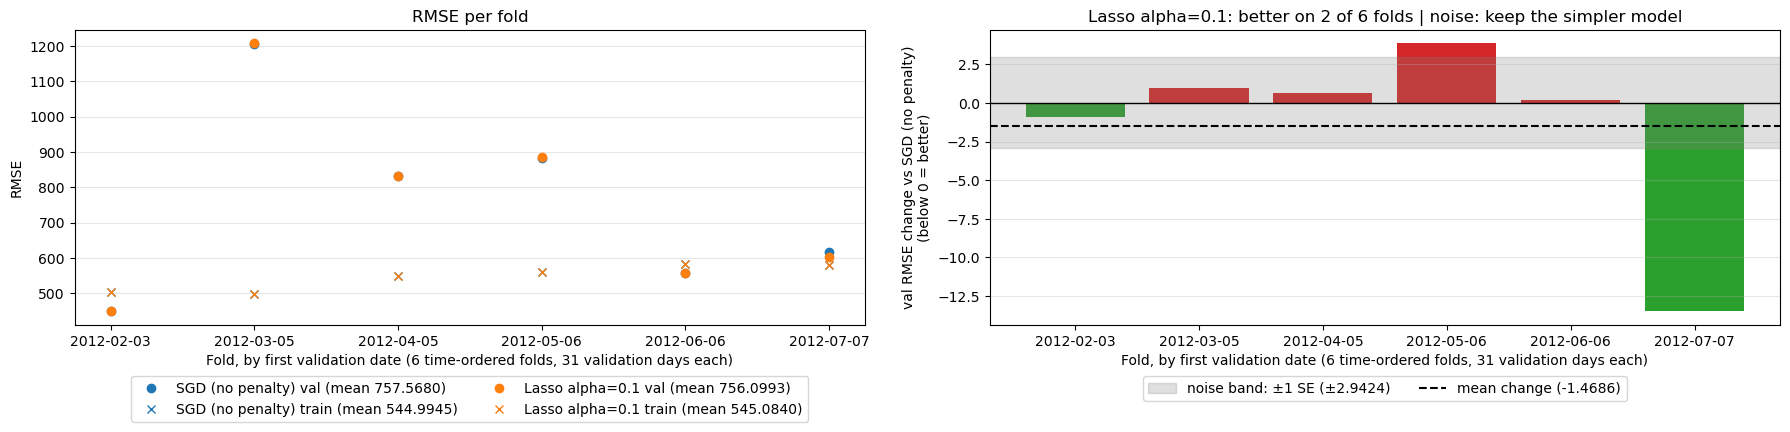

In [18]:
for alpha in ALPHAS:
	lasso_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='l1', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Lasso > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

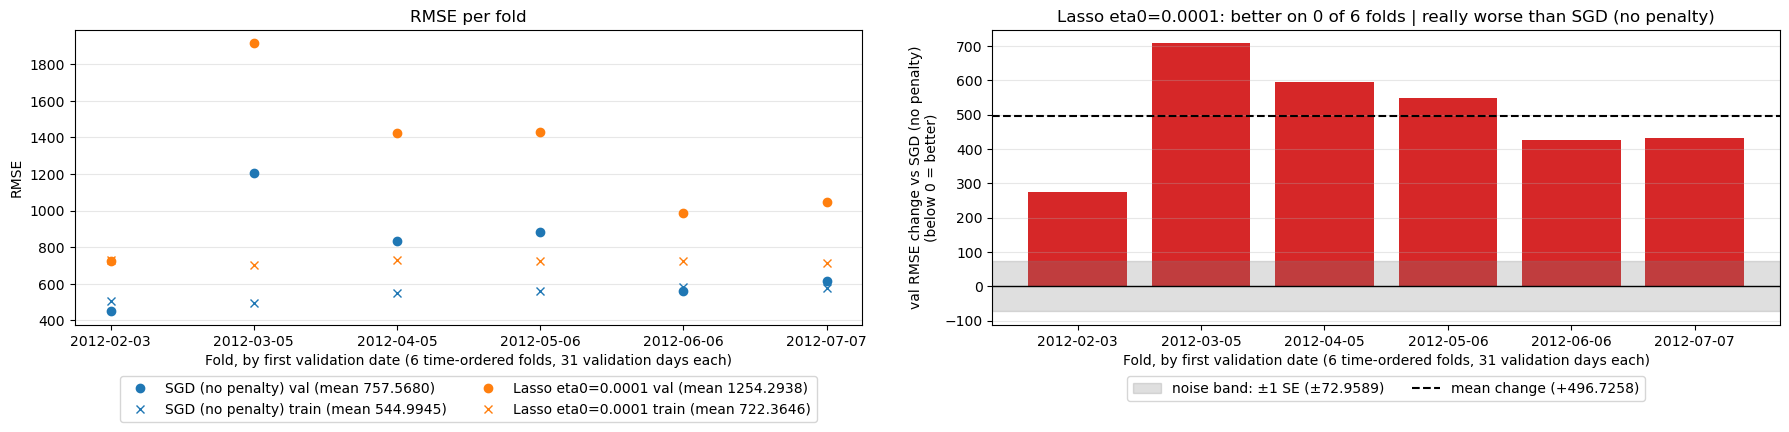

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

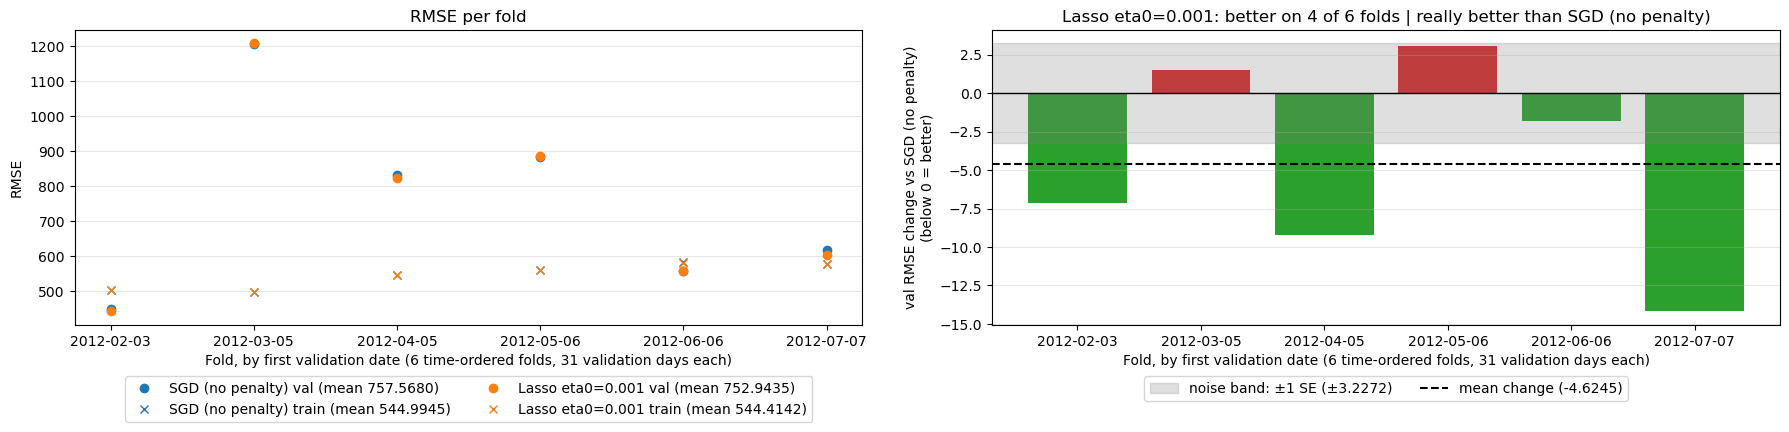

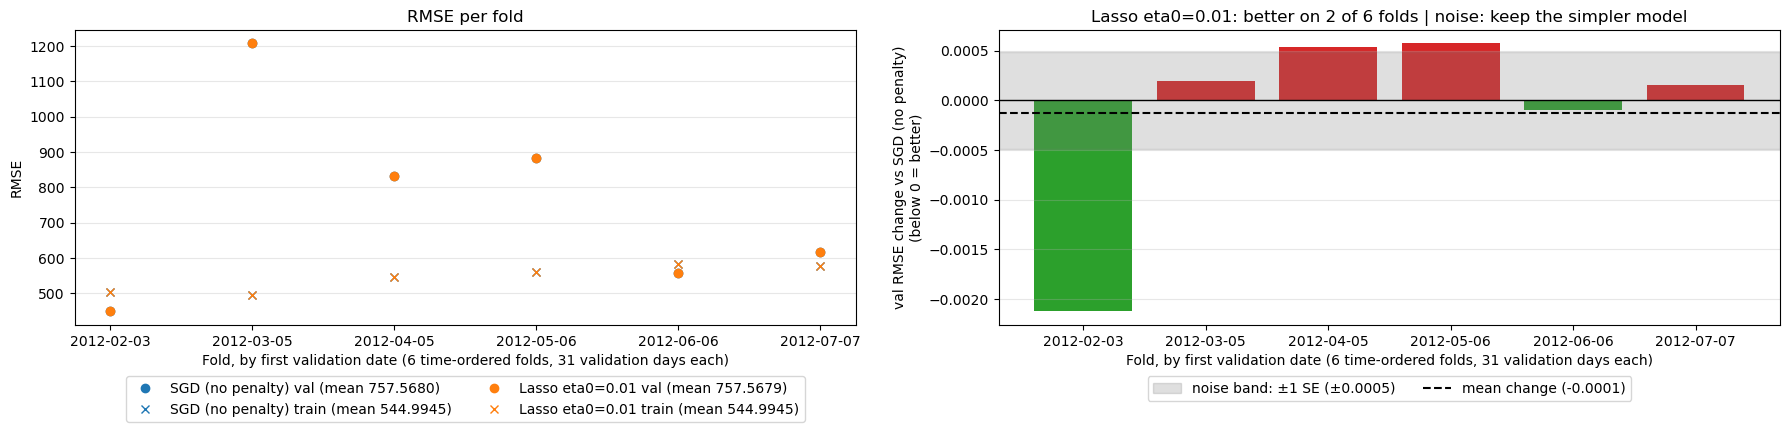

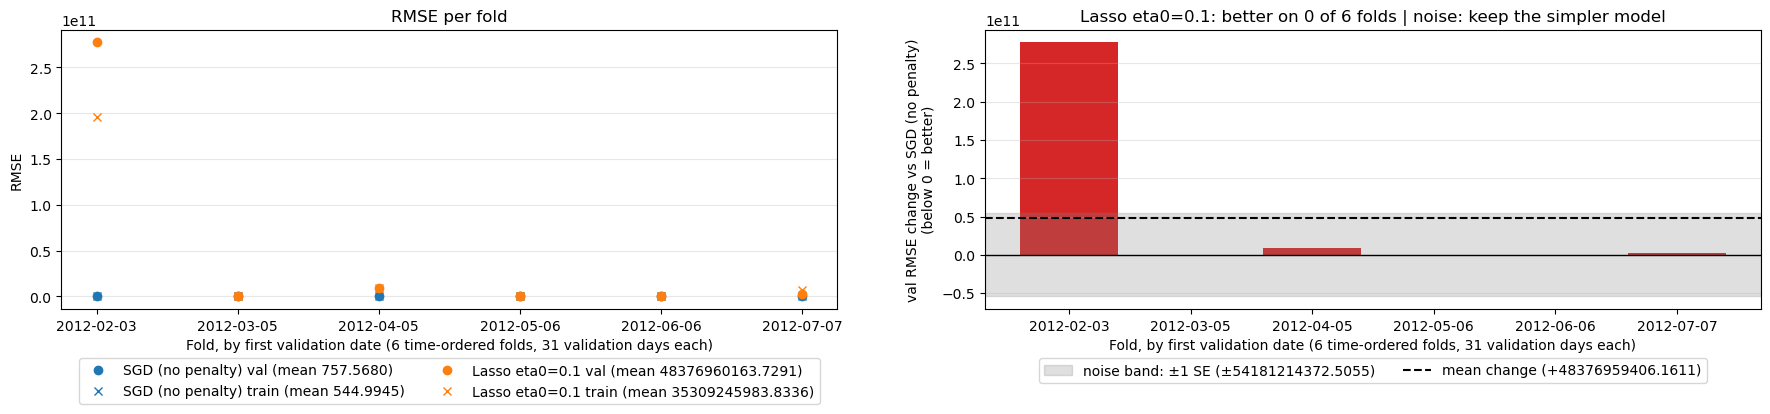

In [19]:
for eta0 in LEARNING_RATES:
	lasso_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='l1', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Ridge

In [20]:
ridge_scores = {}

### Ridge > Penalty

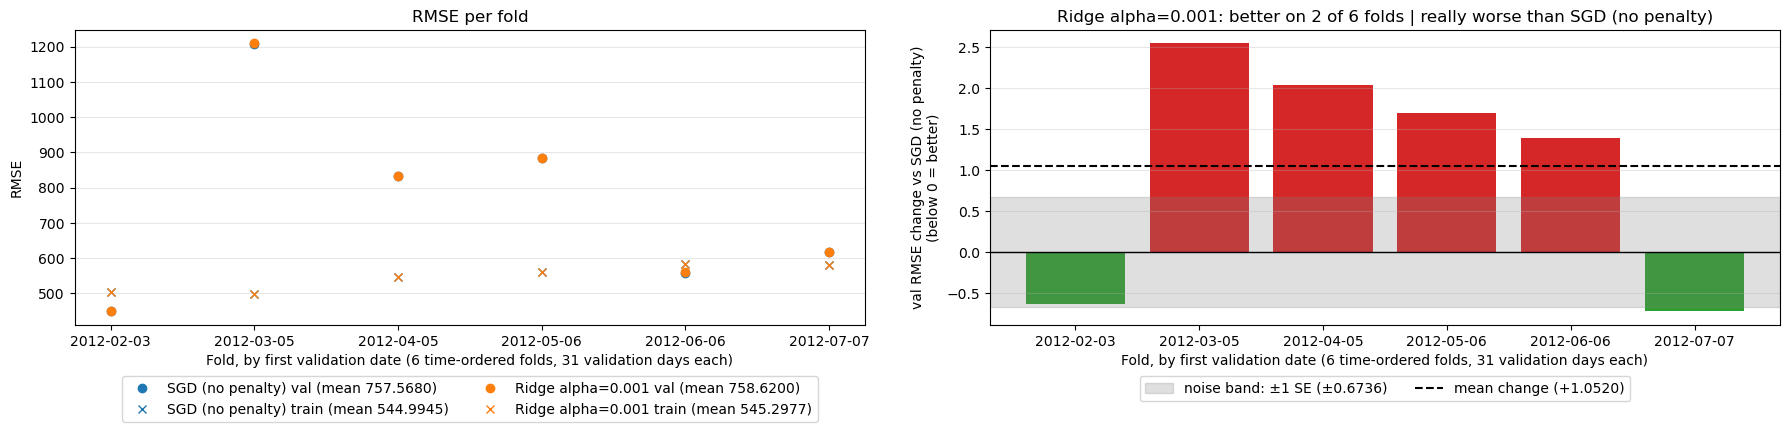

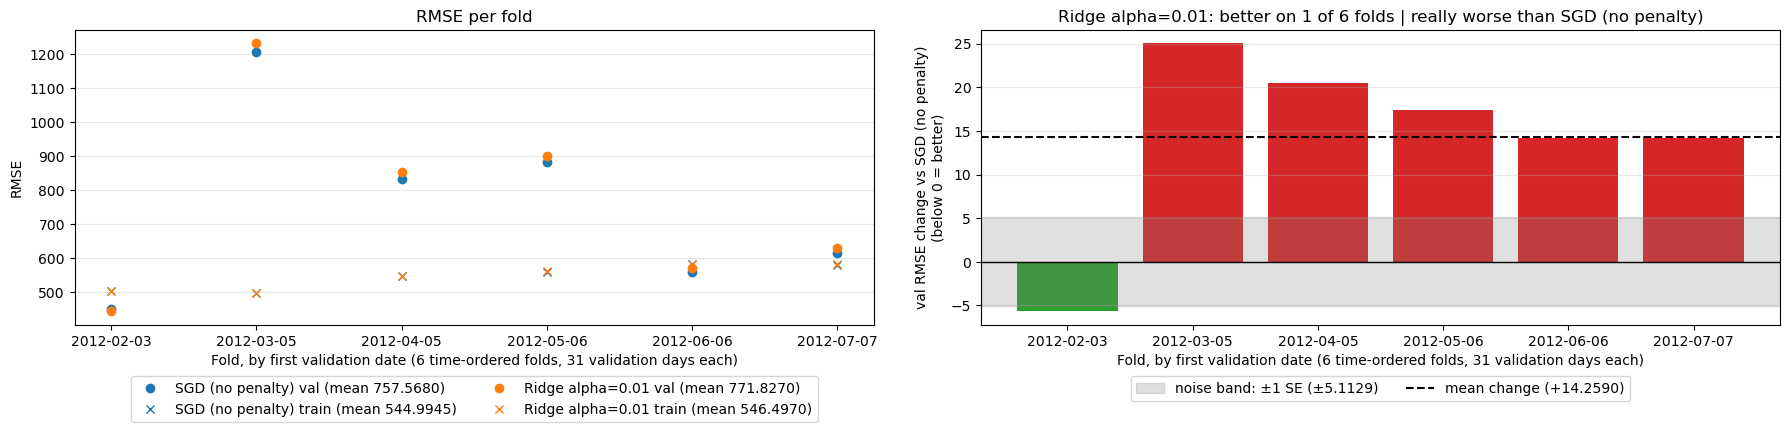

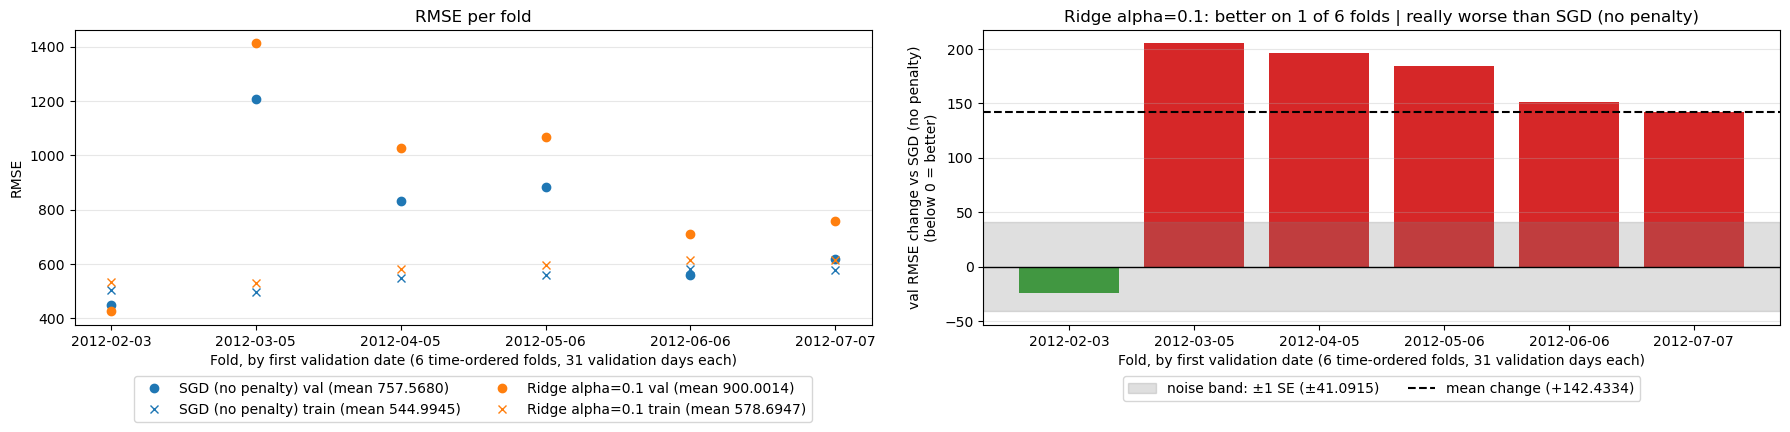

In [21]:
for alpha in ALPHAS:
	ridge_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='l2', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Ridge > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

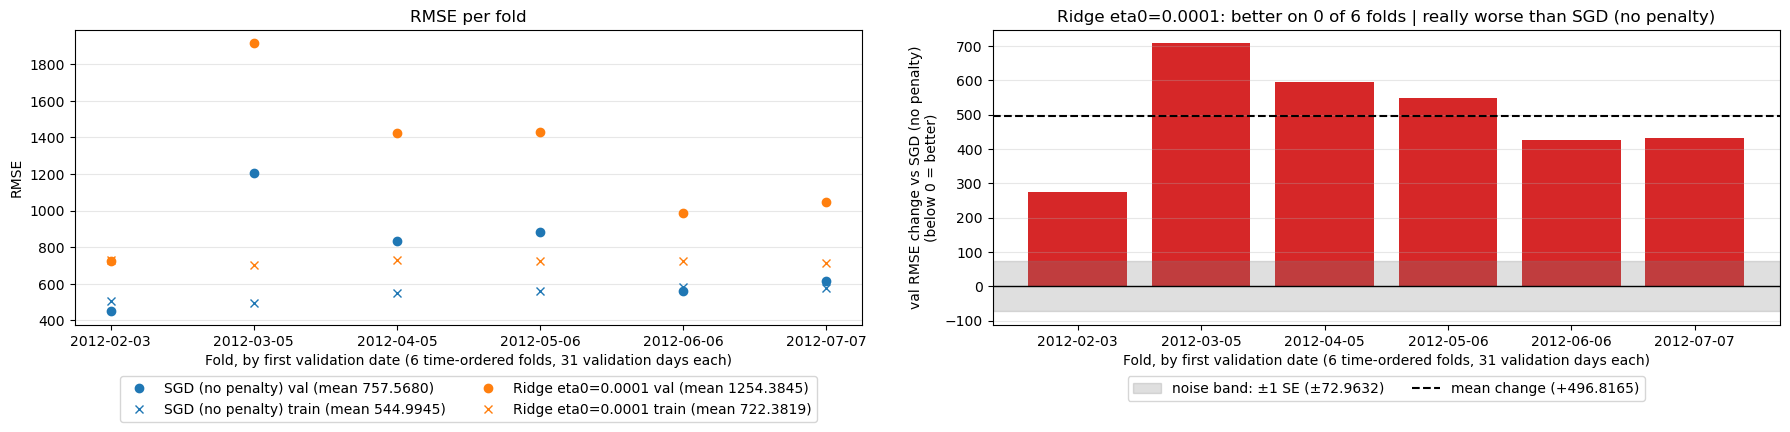

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

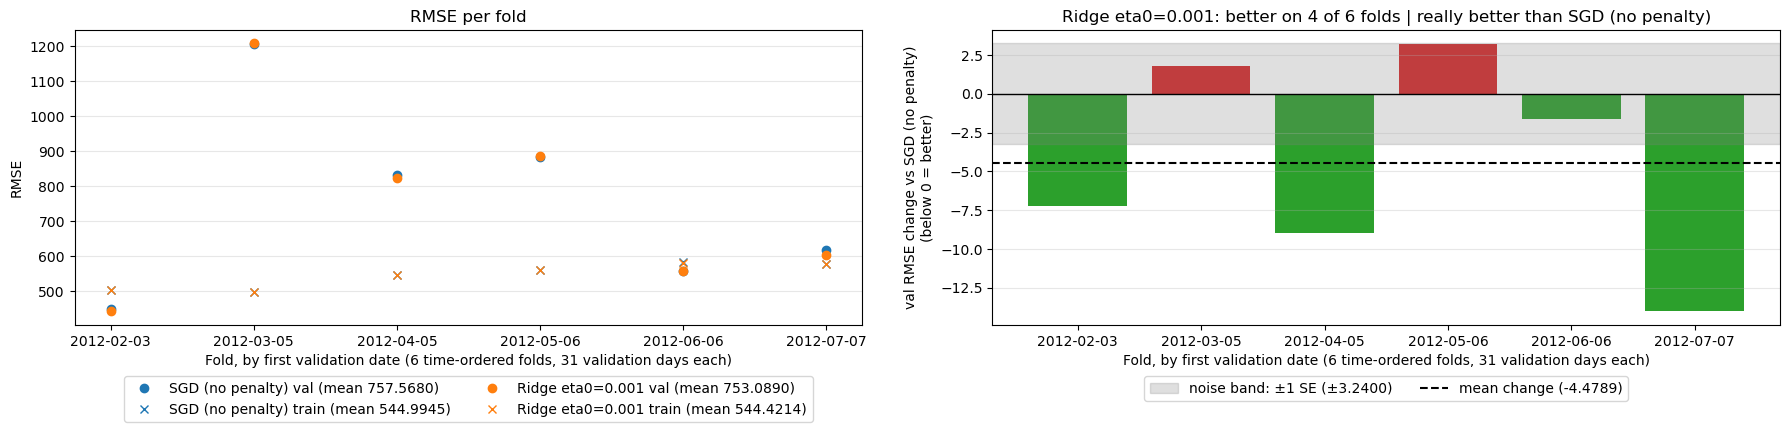

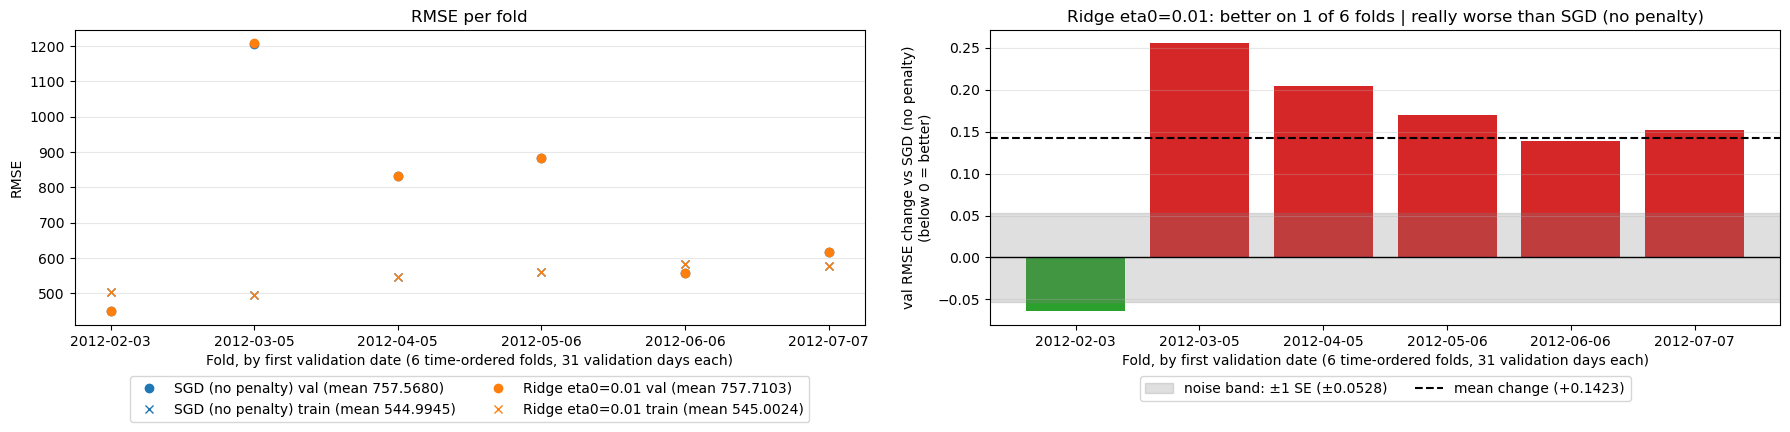

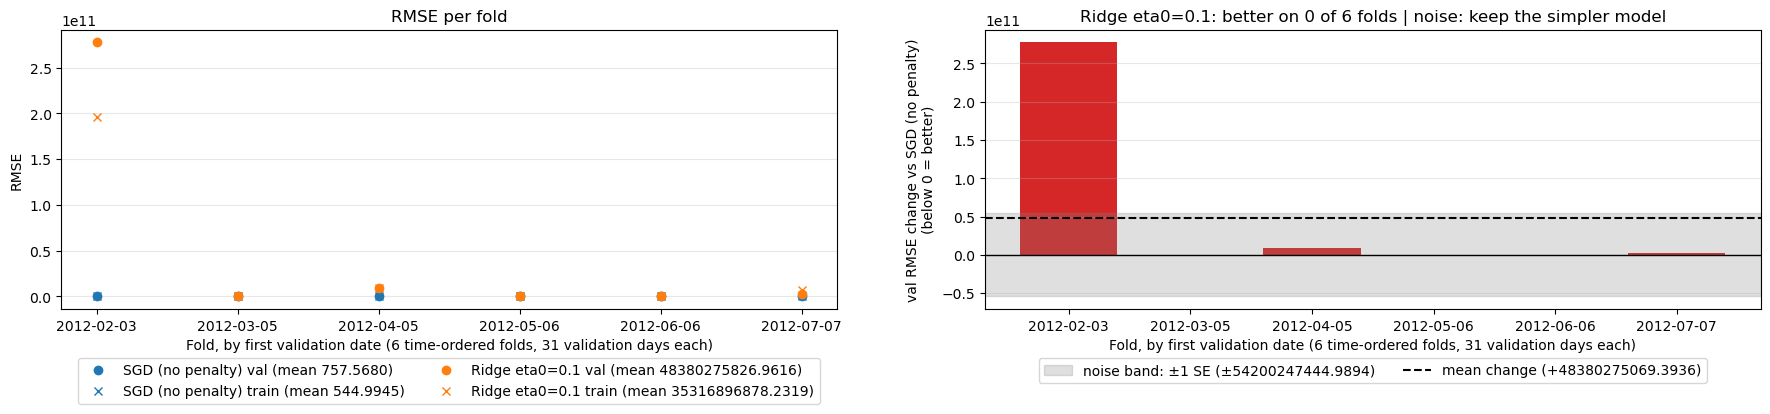

In [22]:
for eta0 in LEARNING_RATES:
	ridge_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='l2', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Elastic Net

In [23]:
elasticnet_scores = {}

### Elastic Net > Penalty

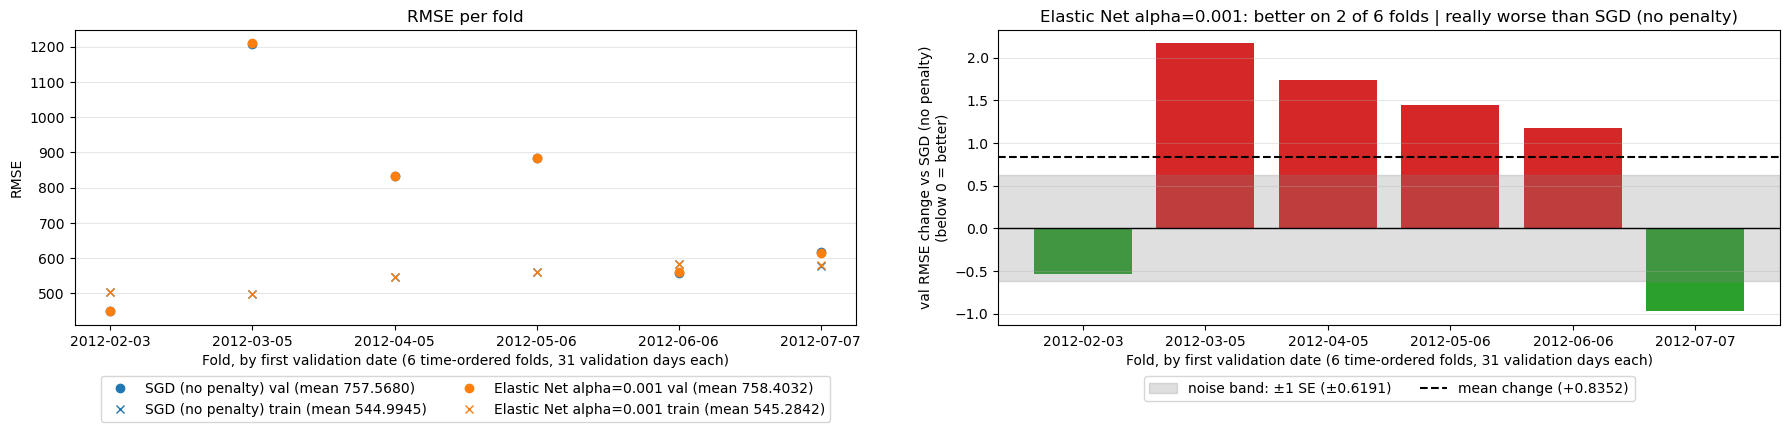

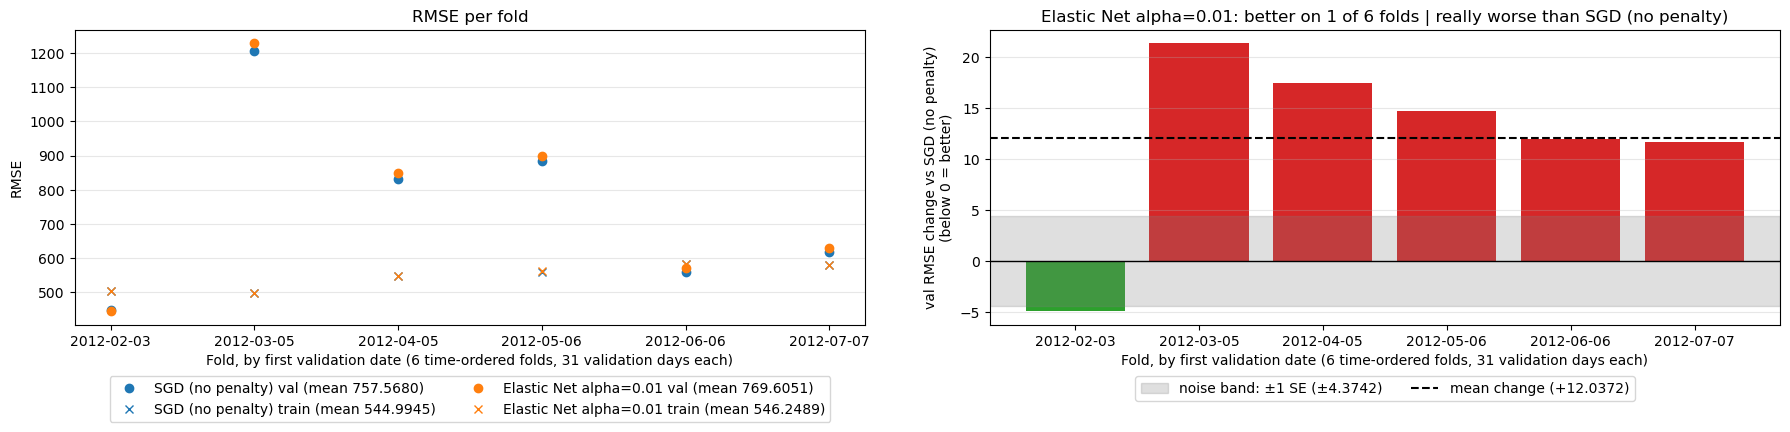

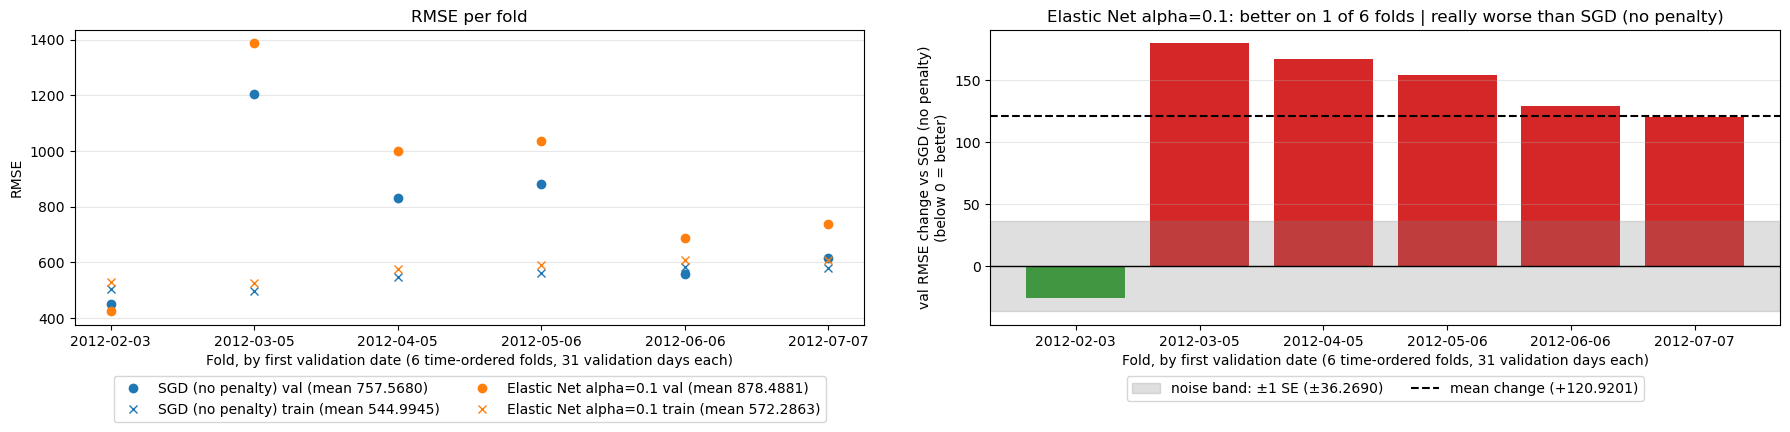

In [24]:
for alpha in ALPHAS:
	elasticnet_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='elasticnet', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Elastic Net > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

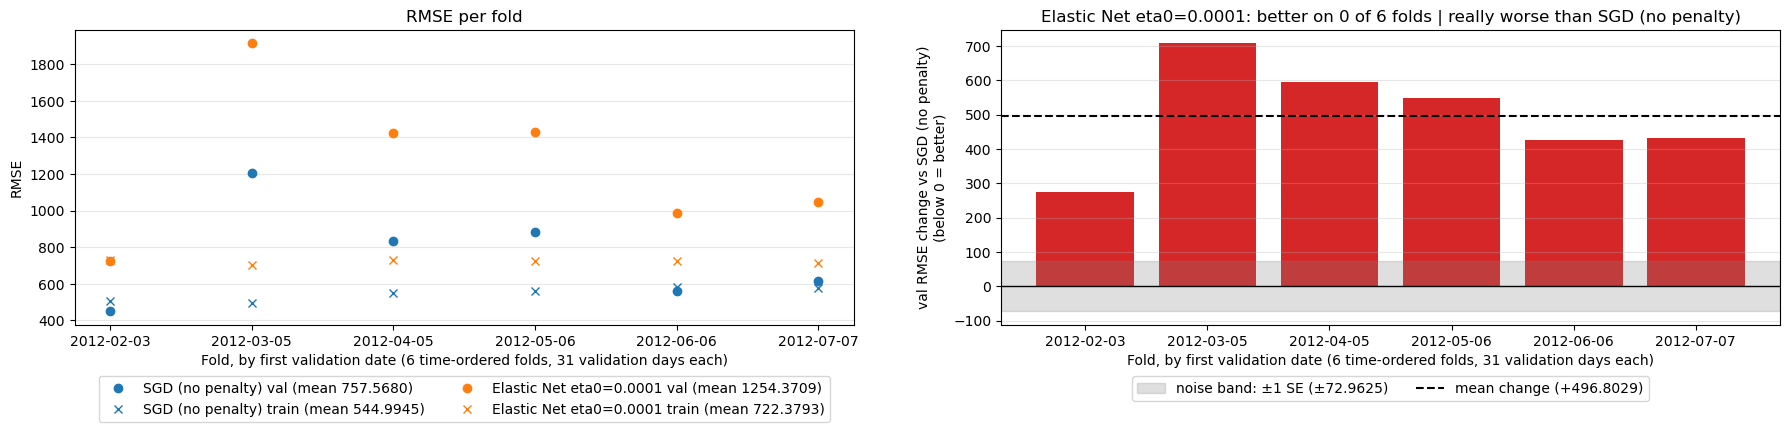

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

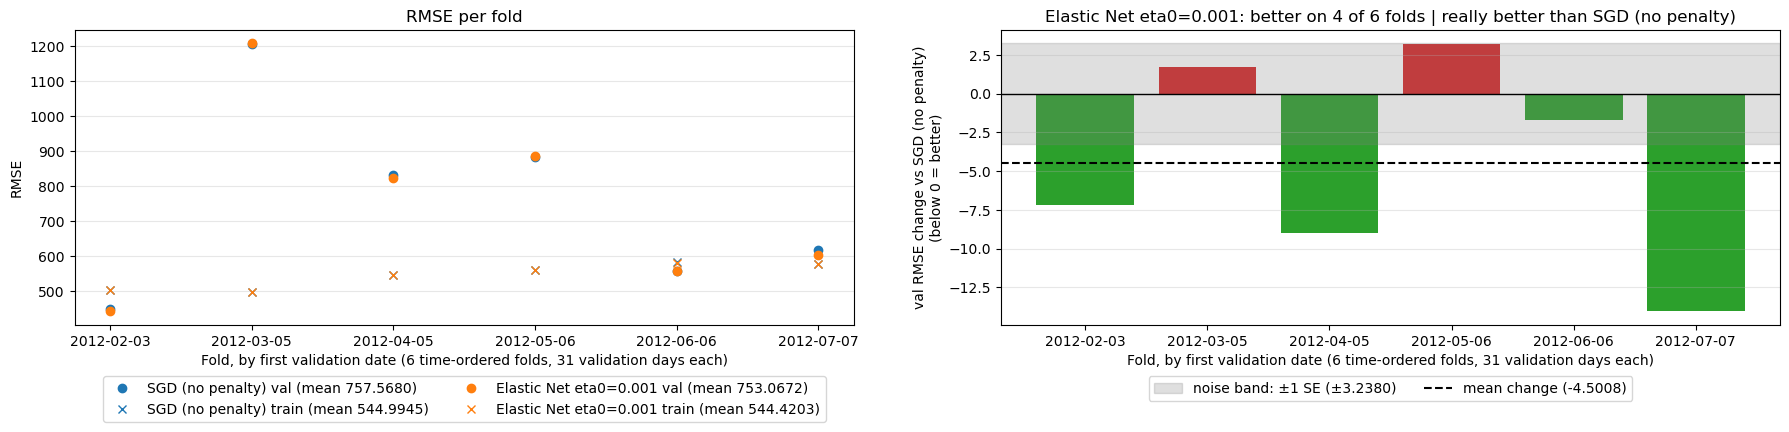

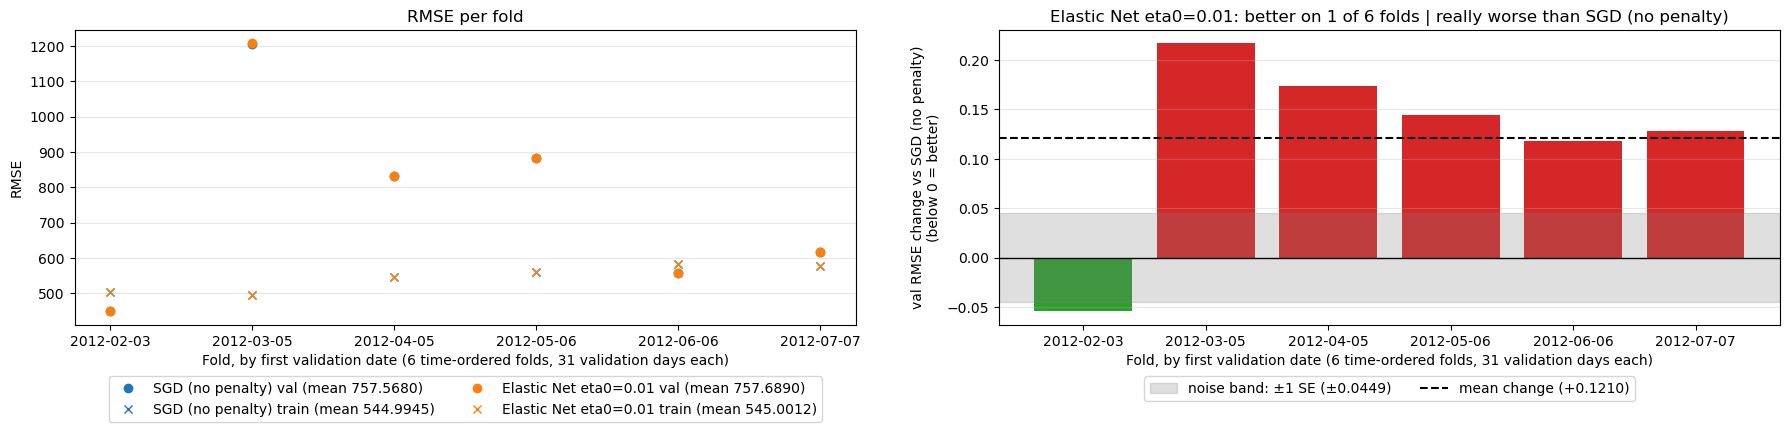

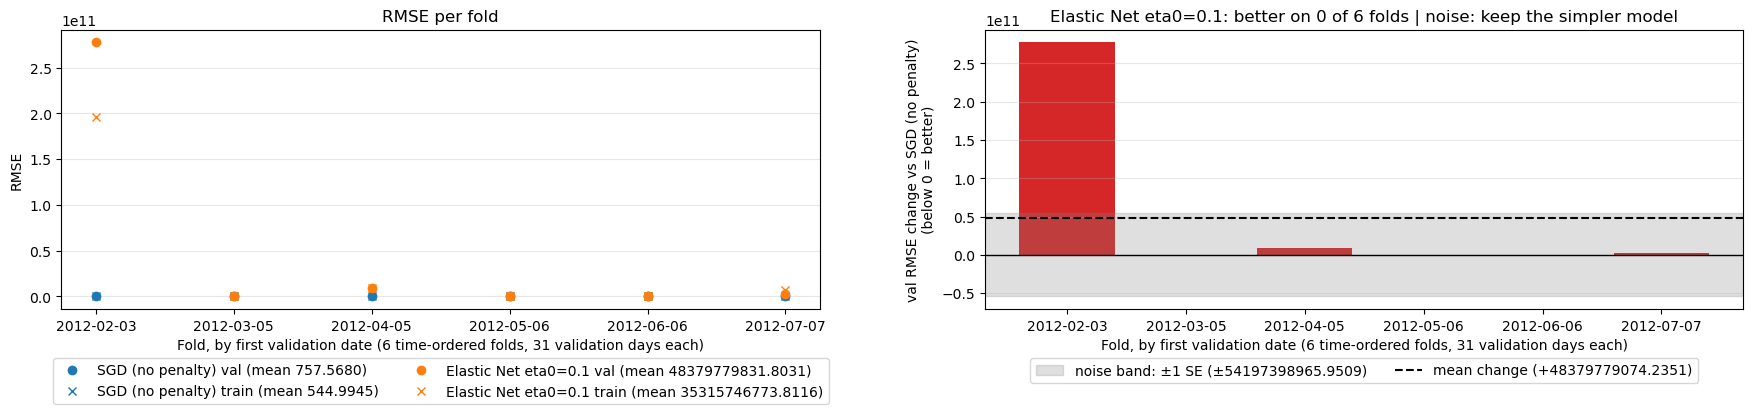

In [25]:
for eta0 in LEARNING_RATES:
	elasticnet_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='elasticnet', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Penalty Summary

In [26]:
runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "alpha":
			runs[f"{name} alpha={value}"] = val_train

summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in runs.items()
}).T.sort_values("change vs SGD")
summary["folds better"] = summary["folds better"].astype(int)
summary.round(4)

,val RMSE,train RMSE,change vs SGD,SE,folds better
Lasso alpha=0.001,755.1147,544.9237,-2.4533,2.8967,3
Lasso alpha=0.01,755.1390,544.9297,-2.4290,2.8766,3
Lasso alpha=0.1,756.0993,545.0840,-1.4686,2.9424,2
SGD (no penalty),757.5680,544.9945,0.0000,0.0000,0
Elastic Net alpha=0.001,758.4032,545.2842,0.8352,0.6191,2
Ridge alpha=0.001,758.6200,545.2977,1.0520,0.6736,2
Elastic Net alpha=0.01,769.6051,546.2489,12.0372,4.3742,1
Ridge alpha=0.01,771.8270,546.4970,14.2590,5.1129,1
Elastic Net alpha=0.1,878.4881,572.2863,120.9201,36.2690,1
Ridge alpha=0.1,900.0014,578.6947,142.4334,41.0915,1


**Impact of the penalty.** Each run changes only alpha and leaves eta0 at its default. No penalty gives a real gain over plain SGD (757.5680). Lasso has the lowest scores at all three alphas: 755.1147 at alpha 0.001 (-2.4533, SE 2.8967), 755.1390 at alpha 0.01 and 756.0993 at alpha 0.1. All three are inside the noise and better on 3, 3 and 2 of 6 folds. Every run with an L2 part is really worse. At alpha 0.001 the cost is small: Elastic Net 758.4032 (+0.8352, SE 0.6191) and Ridge 758.6200 (+1.0520, SE 0.6736). It grows at alpha 0.01 (769.6051 and 771.8270) and is large at alpha 0.1: Elastic Net 878.4881 (+120.9201, SE 36.2690) and Ridge 900.0014 (+142.4334, SE 41.0915). So at the same alpha the L2 penalty costs the most and the L1 penalty the least. Training RMSE rises with validation RMSE (578.6947 for Ridge at alpha 0.1, against 544.9945 for plain SGD), so a strong penalty underfits.

## Learning Rate Summary

In [27]:
learning_rate_runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "eta0":
			learning_rate_runs[f"{name} eta0={value}"] = val_train

learning_rate_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in learning_rate_runs.items()
}).T.sort_values("change vs SGD")
learning_rate_summary["folds better"] = learning_rate_summary["folds better"].astype(int)

# a run that diverged has a val RMSE in the millions or more. Those rows are counted here and left out of
# the table, because numbers that large would force the whole table into scientific notation.
DIVERGED = 1e6
diverged = learning_rate_summary["val RMSE"] > DIVERGED
print(f"diverged (val RMSE above {DIVERGED:.0e}): {diverged.sum()} of {len(learning_rate_summary)} runs: {', '.join(learning_rate_summary[diverged].index)}")
learning_rate_summary[~diverged].round(4)

diverged (val RMSE above 1e+06): 3 of 13 runs: Lasso eta0=0.1, Elastic Net eta0=0.1, Ridge eta0=0.1


,val RMSE,train RMSE,change vs SGD,SE,folds better
Lasso eta0=0.001,752.9435,544.4142,-4.6245,3.2272,4
Elastic Net eta0=0.001,753.0672,544.4203,-4.5008,3.2380,4
Ridge eta0=0.001,753.0890,544.4214,-4.4789,3.2400,4
Lasso eta0=0.01,757.5679,544.9945,-0.0001,0.0005,2
SGD (no penalty),757.5680,544.9945,0.0000,0.0000,0
Elastic Net eta0=0.01,757.6890,545.0012,0.1210,0.0449,1
Ridge eta0=0.01,757.7103,545.0024,0.1423,0.0528,1
Lasso eta0=0.0001,1254.2938,722.3646,496.7258,72.9589,0
Elastic Net eta0=0.0001,1254.3709,722.3793,496.8029,72.9625,0
Ridge eta0=0.0001,1254.3845,722.3819,496.8165,72.9632,0


**Impact of the learning rate.** Each run changes only eta0 and leaves alpha at its default. The three penalties score almost the same at every eta0, so the learning rate is what matters here.

- **eta0 0.001** is the only value that beats plain SGD. Lasso scores 752.9435 (-4.6245, SE 3.2272), Elastic Net 753.0672 and Ridge 753.0890 (-4.4789, SE 3.2400). All three are really better and better on 4 of 6 folds, but the gain is small.
- **eta0 0.01** is the value plain SGD already uses. All three penalties are next to it (757.5679 to 757.7103).
- **eta0 0.0001** is too slow. All three reach about 1254.3 (+496.7258 to +496.8165, SE about 72.96) and are better on 0 of 6 folds. Training RMSE is high too (722.3646, against 544.9945 for plain SGD), so these models are underfit. The `ConvergenceWarning`s under these cells say the same: some runs reach the iteration limit before they converge.
- **eta0 0.1** diverges for all three penalties (a validation RMSE above 1e+06), so those three runs are left out of the table.

## Hyperparameter Grid
Every combination of penalty, alpha and learning rate (eta0), each compared against plain SGD.

In [28]:
grid_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	grid_scores[(penalty, alpha, eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in grid_scores.items()
}).T
grid.index.names = ["penalty", "alpha", "eta0"]
grid["folds better"] = grid["folds better"].astype(int)

# diverged runs are counted and left out of the table, as in the Learning Rate Summary
diverged = grid["val RMSE"] > DIVERGED
print(f"diverged (val RMSE above {DIVERGED:.0e}): {diverged.sum()} of {len(grid)} runs, at eta0 values {sorted(set(grid[diverged].index.get_level_values('eta0')))}")
grid[~diverged].sort_values("val RMSE").round(4)

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

diverged (val RMSE above 1e+06): 9 of 36 runs, at eta0 values [0.1]


val RMSE  train RMSE  change vs SGD       SE  \
penalty    alpha eta0                                                    
l1         0.001 0.0010   752.9443    544.4149        -4.6237   3.2282   
           0.010 0.0010   752.9551    544.4218        -4.6129   3.2367   
           0.100 0.0010   753.2662    544.5202        -4.3018   3.3101   
elasticnet 0.001 0.0010   754.1836    544.4794        -3.3844   3.3617   
l2         0.001 0.0010   754.4022    544.4916        -3.1658   3.3909   
l1         0.001 0.0100   755.1147    544.9237        -2.4533   2.8967   
           0.010 0.0100   755.1390    544.9297        -2.4290   2.8766   
           0.100 0.0100   756.0993    545.0840        -1.4686   2.9424   
elasticnet 0.001 0.0100   758.4032    545.2842         0.8352   0.6191   
l2         0.001 0.0100   758.6200    545.2977         1.0520   0.6736   
elasticnet 0.010 0.0010   765.6596    545.4779         8.0916   6.0640   
l2         0.010 0.0010   767.8990    545.7212        10.3310   6.7182   
elasticnet 0.010 0.0100   769.6051    546.2489        12.0372   4.3742   
l2         0.010 0.0100   771.8270    546.4970        14.2590   5.1129   
elasticnet 0.100 0.0100   878.4881    572.2863       120.9201  36.2690   
                 0.0010   883.3303    573.6282       125.7623  37.1326   
l2         0.100 0.0100   900.0014    578.6947       142.4334  41.0915   
                 0.0010   904.7972    580.5804       147.2292  41.9172   
l1         0.001 0.0001  1254.2966    722.3653       496.7286  72.9590   
           0.010 0.0001  1254.3252    722.3724       496.7572  72.9605   
           0.100 0.0001  1254.6182    722.4430       497.0502  72.9681   
elasticnet 0.001 0.0001  1255.0674    722.5121       497.4995  72.9957   
l2         0.001 0.0001  1255.2034    722.5380       497.6354  73.0022   
elasticnet 0.010 0.0001  1262.0036    723.8478       504.4356  73.3312   
l2         0.010 0.0001  1263.3523    724.1100       505.7843  73.3971   
elasticnet 0.100 0.0001  1328.4672    737.8447       570.8992  76.9912   
l2         0.100 0.0001  1340.8529    740.6769       583.2849  77.7557   

                         folds better  
penalty    alpha eta0                  
l1         0.001 0.0010             4  
           0.010 0.0010             4  
           0.100 0.0010             4  
elasticnet 0.001 0.0010             4  
l2         0.001 0.0010             4  
l1         0.001 0.0100             3  
           0.010 0.0100             3  
           0.100 0.0100             2  
elasticnet 0.001 0.0100             2  
l2         0.001 0.0100             2  
elasticnet 0.010 0.0010             2  
l2         0.010 0.0010             1  
elasticnet 0.010 0.0100             1  
l2         0.010 0.0100             1  
elasticnet 0.100 0.0100             1  
                 0.0010             1  
l2         0.100 0.0100             1  
                 0.0010             1  
l1         0.001 0.0001             0  
           0.010 0.0001             0  
           0.100 0.0001             0  
elasticnet 0.001 0.0001             0  
l2         0.001 0.0001             0  
elasticnet 0.010 0.0001             0  
l2         0.010 0.0001             0  
elasticnet 0.100 0.0001             0  
l2         0.100 0.0001             0

### Elastic Net l1_ratio
Elastic Net only: l1_ratio sets the mix of the two penalties (0 = all Ridge, 1 = all Lasso). Ridge and Lasso ignore it.

In [29]:
L1_RATIOS = [0.15, 0.5, 0.85]

elasticnet_grid_scores = {}
for alpha, eta0, l1_ratio in product(ALPHAS, LEARNING_RATES, L1_RATIOS):
	elasticnet_grid_scores[(alpha, eta0, l1_ratio)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=BEST_DEGREE, model=SGDRegressor(penalty='elasticnet', alpha=alpha, eta0=eta0, l1_ratio=l1_ratio, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

elasticnet_grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in elasticnet_grid_scores.items()
}).T
elasticnet_grid.index.names = ["alpha", "eta0", "l1_ratio"]
elasticnet_grid["folds better"] = elasticnet_grid["folds better"].astype(int)

# diverged runs are counted and left out of the table, as in the Learning Rate Summary
diverged = elasticnet_grid["val RMSE"] > DIVERGED
print(f"diverged (val RMSE above {DIVERGED:.0e}): {diverged.sum()} of {len(elasticnet_grid)} runs, at eta0 values {sorted(set(elasticnet_grid[diverged].index.get_level_values('eta0')))}")
elasticnet_grid[~diverged].sort_values("val RMSE").round(4)

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

diverged (val RMSE above 1e+06): 9 of 36 runs, at eta0 values [0.1]


val RMSE  train RMSE  change vs SGD       SE  \
alpha eta0   l1_ratio                                                  
0.001 0.0010 0.85       753.1622    544.4257        -4.4058   3.2477   
             0.50       753.6740    544.4519        -3.8940   3.2997   
             0.15       754.1836    544.4794        -3.3844   3.3617   
0.010 0.0010 0.85       755.4702    544.6270        -2.0978   3.7121   
0.001 0.0100 0.85       757.7840    545.0071         0.2160   0.0792   
             0.50       758.2816    545.0357         0.7136   0.2640   
             0.15       758.4032    545.2842         0.8352   0.6191   
0.010 0.0100 0.85       759.7434    545.1304         2.1754   0.8004   
      0.0010 0.50       760.3891    544.9789         2.8211   4.6293   
      0.0100 0.50       764.4601    545.7439         6.8921   2.6181   
      0.0010 0.15       765.6596    545.4779         8.0916   6.0640   
      0.0100 0.15       769.6051    546.2489        12.0372   4.3742   
0.100 0.0010 0.85       775.7525    546.7970        18.1845   9.0957   
      0.0100 0.85       779.8671    547.3970        22.2991   7.2733   
             0.50       829.7130    557.9481        72.1450  24.2738   
      0.0010 0.50       831.0998    558.9070        73.5318  24.7725   
      0.0100 0.15       878.4881    572.2863       120.9201  36.2690   
      0.0010 0.15       883.3303    573.6282       125.7623  37.1326   
0.001 0.0001 0.85      1254.4327    722.3912       496.8647  72.9655   
             0.50      1254.7501    722.4516       497.1821  72.9806   
             0.15      1255.0674    722.5121       497.4995  72.9957   
0.010 0.0001 0.85      1255.6850    722.6315       498.1170  73.0252   
             0.50      1258.8501    723.2382       501.2821  73.1773   
             0.15      1262.0036    723.8478       504.4356  73.3312   
0.100 0.0001 0.85      1268.0935    725.0582       510.5255  73.6449   
             0.50      1298.8067    731.3499       541.2387  75.2671   
             0.15      1328.4672    737.8447       570.8992  76.9912   

                       folds better  
alpha eta0   l1_ratio                
0.001 0.0010 0.85                 4  
             0.50                 4  
             0.15                 4  
0.010 0.0010 0.85                 3  
0.001 0.0100 0.85                 1  
             0.50                 1  
             0.15                 2  
0.010 0.0100 0.85                 1  
      0.0010 0.50                 2  
      0.0100 0.50                 1  
      0.0010 0.15                 2  
      0.0100 0.15                 1  
0.100 0.0010 0.85                 1  
      0.0100 0.85                 1  
             0.50                 1  
      0.0010 0.50                 1  
      0.0100 0.15                 1  
      0.0010 0.15                 1  
0.001 0.0001 0.85                 0  
             0.50                 0  
             0.15                 0  
0.010 0.0001 0.85                 0  
             0.50                 0  
             0.15                 0  
0.100 0.0001 0.85                 0  
             0.50                 0  
             0.15                 0

**Impact of combining the hyperparameters, and of l1_ratio.** Nine of the 36 grid runs diverge, all of them at eta0 0.1, and are left out. The 27 that remain sort by eta0 and by how strong the L2 penalty is. The five best rows all use eta0 0.001 and are better on 4 of 6 folds: Lasso at all three alphas (752.9443, 752.9551 and 753.2662), then Elastic Net and Ridge at alpha 0.001 (754.1836 and 754.4022). Lasso at eta0 0.01 follows (755.1147 to 756.0993). Every eta0 0.0001 row is at the bottom (1254.2966 to 1340.8529), and Ridge and Elastic Net at alpha 0.1 score 878.4881 or worse at both remaining learning rates. The best row, Lasso with alpha 0.001 and eta0 0.001 (752.9443, -4.6237, SE 3.2282), is really better than plain SGD by a small margin. It pairs the best alpha and the best eta0 of the single experiments, so no combination beats choosing them one at a time.

l1_ratio matters more as alpha grows, and more L1 is better at every alpha. At eta0 0.001 the three l1_ratio values (0.85, 0.5, 0.15) score 753.1622, 753.6740 and 754.1836 at alpha 0.001, then 755.4702, 760.3891 and 765.6596 at alpha 0.01, then 775.7525, 831.0998 and 883.3303 at alpha 0.1. This matches the penalty findings: the L2 part of the penalty is what costs the most.

## Degree Check
The degree was selected with closed form, which has no penalty. This section checks that choice with SGD: the same Hyperparameter Grid one degree higher, compared against plain SGD at degree `BEST_DEGREE`. It shows whether a penalty makes the higher degree worth its extra columns.

In [30]:
CHECK_DEGREE = BEST_DEGREE + 1

degree_check_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	degree_check_scores[(penalty, alpha, eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=ATTRIBUTES,
		estimator=poly_pipeline(degree=CHECK_DEGREE, model=SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

degree_check = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in degree_check_scores.items()
}).T
degree_check.index.names = ["penalty", "alpha", "eta0"]
degree_check["folds better"] = degree_check["folds better"].astype(int)

# diverged runs are counted and left out of the table, as in the Learning Rate Summary
diverged = degree_check["val RMSE"] > DIVERGED
print(f"diverged (val RMSE above {DIVERGED:.0e}): {diverged.sum()} of {len(degree_check)} runs, at eta0 values {sorted(set(degree_check[diverged].index.get_level_values('eta0')))}")
degree_check[~diverged].sort_values("val RMSE").round(4)

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

diverged (val RMSE above 1e+06): 9 of 36 runs, at eta0 values [0.1]


val RMSE  train RMSE  change vs SGD        SE  \
penalty    alpha eta0                                                     
l1         0.001 0.0010   765.1744    526.3269         7.6065   18.2934   
           0.010 0.0010   765.2049    526.3414         7.6370   18.2904   
           0.100 0.0010   765.5616    526.3326         7.9936   18.3620   
elasticnet 0.001 0.0010   766.4700    526.3144         8.9020   18.2694   
l2         0.001 0.0010   766.6847    526.3404         9.1167   18.2535   
elasticnet 0.010 0.0010   777.6011    528.0817        20.0331   17.9661   
l2         0.010 0.0010   779.8001    528.4564        22.2321   18.0198   
elasticnet 0.100 0.0010   890.9214    560.7519       133.3534   37.7952   
l2         0.100 0.0010   911.8600    568.0031       154.2920   42.0010   
elasticnet 0.100 0.0100  1064.2147    890.2840       306.6468  180.1375   
l2         0.100 0.0100  1065.5554    866.0548       307.9874  150.9220   
           0.010 0.0100  1110.6106   1076.9656       353.0426  373.1088   
l1         0.100 0.0100  1110.7171   1099.4686       353.1491  396.9408   
elasticnet 0.010 0.0100  1111.8987   1081.6956       354.3307  377.7117   
l2         0.001 0.0100  1118.0326   1107.0663       360.4646  402.4780   
elasticnet 0.001 0.0100  1118.1721   1107.5733       360.6041  402.9616   
l1         0.010 0.0100  1118.2675   1109.4773       360.6995  404.8923   
           0.001 0.0100  1118.9622   1110.4579       361.3943  405.7107   
                 0.0001  1251.6580    707.0030       494.0900   84.0370   
           0.010 0.0001  1251.6860    707.0096       494.1180   84.0397   
           0.100 0.0001  1251.9651    707.0764       494.3971   84.0684   
elasticnet 0.001 0.0001  1252.4088    707.1475       494.8408   84.0396   
l2         0.001 0.0001  1252.5412    707.1730       494.9732   84.0400   
elasticnet 0.010 0.0001  1259.1673    708.4637       501.5993   84.0719   
l2         0.010 0.0001  1260.4817    708.7223       502.9137   84.0790   
elasticnet 0.100 0.0001  1324.1491    722.3380       566.5811   85.0234   
l2         0.100 0.0001  1336.2829    725.1591       578.7149   85.3330   

                         folds better  
penalty    alpha eta0                  
l1         0.001 0.0010             2  
           0.010 0.0010             2  
           0.100 0.0010             2  
elasticnet 0.001 0.0010             2  
l2         0.001 0.0010             2  
elasticnet 0.010 0.0010             2  
l2         0.010 0.0010             2  
elasticnet 0.100 0.0010             0  
l2         0.100 0.0010             0  
elasticnet 0.100 0.0100             0  
l2         0.100 0.0100             0  
           0.010 0.0100             1  
l1         0.100 0.0100             2  
elasticnet 0.010 0.0100             1  
l2         0.001 0.0100             2  
elasticnet 0.001 0.0100             2  
l1         0.010 0.0100             2  
           0.001 0.0100             2  
                 0.0001             0  
           0.010 0.0001             0  
           0.100 0.0001             0  
elasticnet 0.001 0.0001             0  
l2         0.001 0.0001             0  
elasticnet 0.010 0.0001             0  
l2         0.010 0.0001             0  
elasticnet 0.100 0.0001             0  
l2         0.100 0.0001             0

**Does a penalty make the higher degree worth it?** No. No degree 4 row is better than plain SGD at degree 3 (757.5680).

- **eta0 0.001** is the only learning rate that works at degree 4. The five best rows score 765.1744 to 766.6847, led by Lasso at alpha 0.001 (+7.6065, SE 18.2934, better on 2 of 6 folds). All five are within noise. Their training RMSE is lower than degree 3's (526.3269 against 544.9945), so the extra columns fit the training rows better without helping the days that follow.
- **A stronger penalty does not rescue it.** At eta0 0.001, Elastic Net and Ridge at alpha 0.1 score 890.9214 and 911.8600, both really worse.
- **eta0 0.01** is unstable at degree 4. Its nine rows score 1064.2147 to 1118.9622, with training RMSE between 866.0548 and 1110.4579 and SEs of 150.9220 to 405.7107. They stay below the divergence cut-off, but they are not usable fits.
- **eta0 0.1** diverges on all 9 runs, and **eta0 0.0001** underfits (1251.6580 or worse).

So degree 4 needs a more careful learning rate than degree 3 and gives nothing back for its 76 columns.

# Selected Model
The best-performing row of the Hyperparameter Grid at degree `BEST_DEGREE`: the row with the lowest validation RMSE. It is typed in by hand.

In [31]:
# Typed by hand: the top row of the Hyperparameter Grid above (lowest validation RMSE).
BEST_PENALTY = 'l1'
BEST_ALPHA = 0.001
BEST_ETA0 = 0.001

best_val_scores, best_train_scores = grid_scores[(BEST_PENALTY, BEST_ALPHA, BEST_ETA0)]
print(f"val RMSE {best_val_scores.mean():.4f} | train RMSE {best_train_scores.mean():.4f}")

val RMSE 752.9443 | train RMSE 544.4149


## Selected Model Against the Best Degree 4 Row
The Degree Check compares every degree 4 row with plain SGD at degree 3, not with the selected model. Here the best degree 4 row is compared with the selected model directly, on the same 6 folds. The degree 4 row is typed in by hand from the Degree Check table.

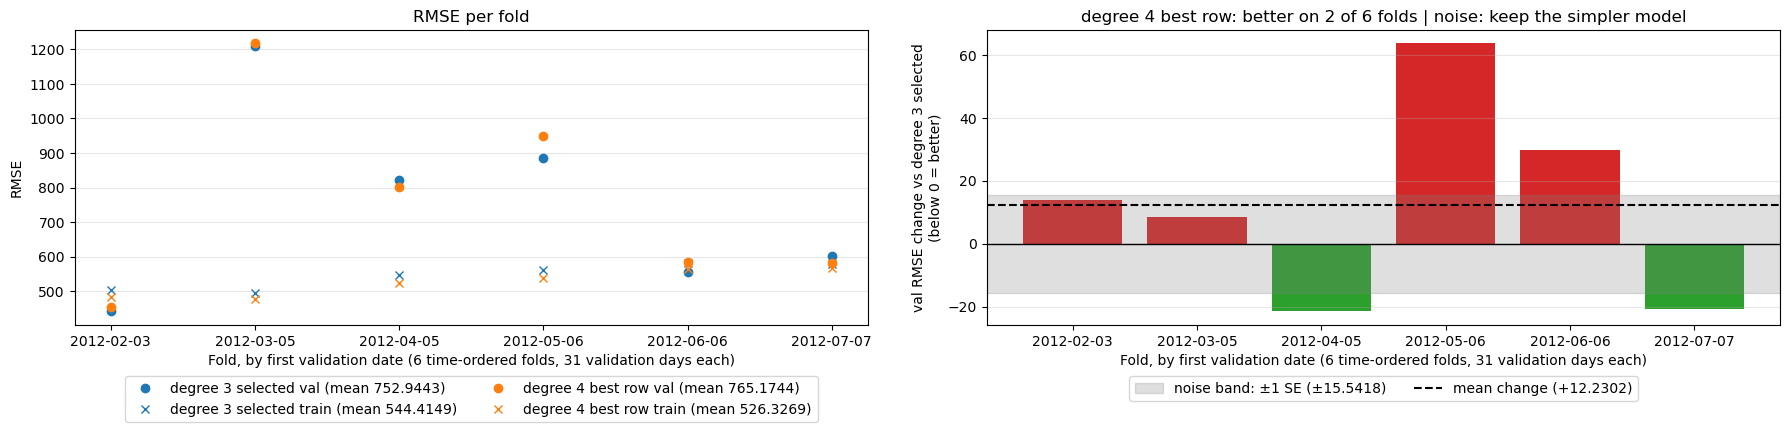

In [32]:
# Typed by hand: the top row of the Degree Check table above (lowest validation RMSE).
CHECK_PENALTY = 'l1'
CHECK_ALPHA = 0.001
CHECK_ETA0 = 0.001

check_val_scores, check_train_scores = degree_check_scores[(CHECK_PENALTY, CHECK_ALPHA, CHECK_ETA0)]

Q2_PLOTTING.cv_fold_scores(
	baseline=(best_val_scores, best_train_scores),
	compare=(check_val_scores, check_train_scores),
	baseline_name=f"degree {BEST_DEGREE} selected",
	compare_name=f"degree {CHECK_DEGREE} best row",
	folds=FOLDS,
	dates=train_df["Date"],
)

**Degree 3 or degree 4.** The selected degree 3 row (Lasso, alpha 0.001, eta0 0.001) scores a validation RMSE of 752.9443. The best degree 4 row (Lasso, alpha 0.001, eta0 0.001) scores 765.1744 and is better on 2 of 6 folds. The mean change of +12.2302 is inside the ±15.5418 noise band, so the verdict is noise and the simpler degree 3 is kept. Degree 4 has the lower training RMSE (526.3269 against 544.4149), so it fits the training rows better and the validation days no better. The fold that starts on 2012-05-06 is where it loses the most, by about 64.

## Train on the Entire Training Set
The selected model is fit once on every training row, with SGD's default stopping rule. The pipeline takes the 11 raw attributes and builds its polynomial columns itself, so it needs no preprocessing outside it.

In [33]:
print(f"rows: {len(train_df)}")

final_model = poly_pipeline(
	degree=BEST_DEGREE,
	model=SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, random_state=42),
)
final_model.fit(train_df[ATTRIBUTES], train_df[TARGET])

final_train_rmse = Q2_CROSS_VALIDATION.rmse_of(train_df[TARGET], final_model.predict(train_df[ATTRIBUTES]))
print(f"train RMSE {final_train_rmse:.4f} | epochs run {final_model[-1].n_iter_}")

rows: 584
train RMSE 579.3917 | epochs run 814


**Final model.** The selected model (degree 3, Lasso, alpha 0.001, eta0 0.001) is trained on all 584 training rows. SGD stops by itself after 814 epochs with a training RMSE of 579.3917. That is above the cross-validated training RMSE of 544.4149. The folds train on the earliest 398 to 553 rows, and in the fold charts training RMSE climbs as later days are added, so fitting every row continues that climb. This model has no validation score of its own, because every training row was used to fit it. The cross-validated validation RMSE of 752.9443 is the estimate of how it scores on days it has not seen, with the limit noted in Method: the folds look 31 days ahead and the test set covers 147 days.

## Save the Model
The fitted pipeline is saved to `Q2/MODELS`, so a later part can load it and predict on the test data.

In [34]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / 'polynomial_regression.joblib'
joblib.dump(final_model, model_path)
print(f"saved: {model_path.name}")

saved: polynomial_regression.joblib


## Training and Validation Loss by Epoch
A validation loss needs rows the model has not trained on, so this curve uses the last of the 6 folds, which has the most training rows: the model trains on that fold's training rows and is scored on its validation rows after every epoch. Each `fit` call runs exactly one epoch (`max_iter=1`) and continues from the previous call (`warm_start=True`). `tol=None` turns off early stopping, so every call runs its one epoch. The curve runs for 1500 epochs, long enough for both lines to go flat.

In [35]:
EPOCHS = 1500

train_index, val_index = FOLDS[-1]
epoch_train_df = train_df.loc[train_index]
epoch_val_df = train_df.loc[val_index]
print(f"train rows: {len(epoch_train_df)} | validation rows: {len(epoch_val_df)}")

epoch_model = poly_pipeline(
	degree=BEST_DEGREE,
	model=SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
)

epoch_train_rmse, epoch_val_rmse = [], []
for epoch in range(EPOCHS):
	# one more epoch, continuing from the coefficients of the previous call
	epoch_model.fit(epoch_train_df[ATTRIBUTES], epoch_train_df[TARGET])
	epoch_train_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_train_df[TARGET], epoch_model.predict(epoch_train_df[ATTRIBUTES])))
	epoch_val_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_val_df[TARGET], epoch_model.predict(epoch_val_df[ATTRIBUTES])))

epoch_scores = pd.DataFrame(
	{"train RMSE": epoch_train_rmse, "val RMSE": epoch_val_rmse},
	index=pd.RangeIndex(1, EPOCHS + 1, name="epoch"),
)
print(f"lowest val RMSE {epoch_scores['val RMSE'].min():.4f} at epoch {epoch_scores['val RMSE'].idxmin()}")
epoch_scores.loc[[1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 1500]].round(4)

train rows: 553 | validation rows: 31
lowest val RMSE 600.2400 at epoch 144


,train RMSE,val RMSE
epoch,,
1,3665.7843,5222.7953
2,3154.3825,4439.2119
3,2729.2524,3879.5826
5,2068.9984,3051.9027
10,1145.8082,1817.7940
20,674.8370,940.4689
50,593.9130,635.7164
100,582.4594,602.4742
200,579.1126,601.4251


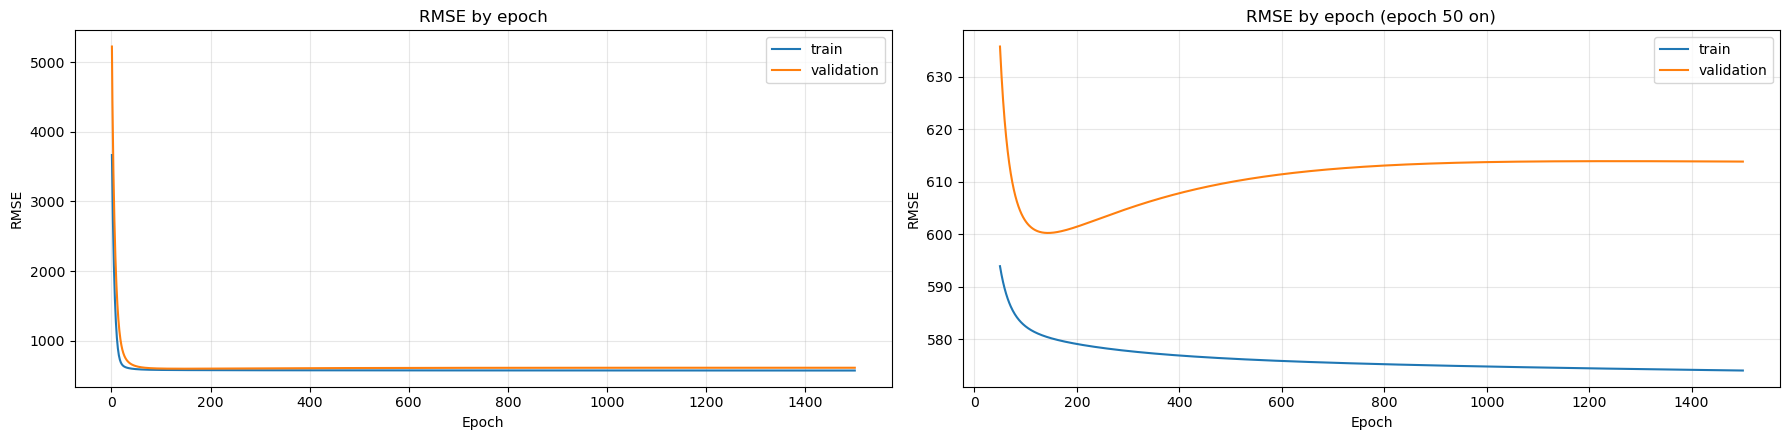

In [36]:
EPOCH_ZOOM = 50

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(18, 4.5))

# left: every epoch. right: from epoch 50 on, where the two lines can be told apart
for ax, scores, title in [
	(ax_all, epoch_scores, "RMSE by epoch"),
	(ax_zoom, epoch_scores.loc[EPOCH_ZOOM:], f"RMSE by epoch (epoch {EPOCH_ZOOM} on)"),
]:
	ax.plot(scores.index, scores["train RMSE"], color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], color="C1", label="validation")
	ax.set_xlabel("Epoch")
	ax.set_ylabel("RMSE")
	ax.set_title(title)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

**Training and validation loss by epoch.** The curve uses the last fold: 553 training rows and 31 validation rows. With eta0 0.001 the learning takes tens of epochs, not one or two. Training RMSE falls from 3665.7843 at epoch 1 to 1145.8082 at epoch 10 and 674.8370 at epoch 20, and validation RMSE from 5222.7953 to 1817.7940 and 940.4689. By epoch 100 they are at 582.4594 and 602.4742.

Validation RMSE is lowest at epoch 144 (600.2400). After that the two lines separate. Training RMSE keeps falling slowly (579.1126 at epoch 200, 576.3181 at epoch 500, 574.0594 at epoch 1500), while validation RMSE rises (601.4251 at epoch 200, 609.9232 at epoch 500, 613.7215 at epoch 1000). Training RMSE falling while validation RMSE rises is the pattern of overfitting. Here it is mild and it levels off: validation RMSE is 613.8214 at epoch 1500, almost where it was at epoch 1000.

On this fold the validation RMSE (about 600 to 614) is much closer to the training RMSE (about 574 to 582) than in the six-fold means (752.9443 against 544.4149). The last fold is one of the easier ones, so the curve shows the shape of the learning, not the typical size of the gap.

# Overfitting and Underfitting
The assignment asks whether the model overfits or underfits, judged by validation loss. Two views are already above: by degree (Degree Summary) and by penalty strength (Penalty Summary). This section adds the third view, by epoch, for degrees 2, 3 and 4: one degree below the selected degree, the selected degree and one degree above.

## Loss by Epoch for Degrees 2, 3 and 4
Plain SGD (no penalty) on the last fold, the same rows as the curve above. The degree is the only thing that changes. All three degrees use eta0 0.001, a learning rate from `LEARNING_RATES` at which none of the three diverges. That learning rate is slow, so the curves run for 2000 epochs.

In [37]:
CURVE_EPOCHS = 2000
CURVE_ETA0 = 0.001
# one degree below the selected degree, the selected degree, one degree above (1, 2, 3 when the selected degree is 1)
CURVE_DEGREES = [max(BEST_DEGREE - 1, 1) + step for step in range(3)]

curve_scores = {}
for degree in CURVE_DEGREES:
	curve_model = poly_pipeline(
		degree=degree,
		model=SGDRegressor(penalty=None, eta0=CURVE_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
	)

	curve_train_rmse, curve_val_rmse = [], []
	for epoch in range(CURVE_EPOCHS):
		# one more epoch, continuing from the coefficients of the previous call
		curve_model.fit(epoch_train_df[ATTRIBUTES], epoch_train_df[TARGET])
		curve_train_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_train_df[TARGET], curve_model.predict(epoch_train_df[ATTRIBUTES])))
		curve_val_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_val_df[TARGET], curve_model.predict(epoch_val_df[ATTRIBUTES])))

	curve_scores[f"degree {degree}"] = pd.DataFrame(
		{"train RMSE": curve_train_rmse, "val RMSE": curve_val_rmse},
		index=pd.RangeIndex(1, CURVE_EPOCHS + 1, name="epoch"),
	)
	print(f"degree {degree}: lowest val RMSE {min(curve_val_rmse):.4f} at epoch {curve_scores[f'degree {degree}']['val RMSE'].idxmin()}")

pd.concat(curve_scores, axis=1).loc[[1, 10, 20, 50, 100, 200, 500, 1000, 1500, 2000]].round(4)

degree 2: lowest val RMSE 770.0042 at epoch 87
degree 3: lowest val RMSE 600.2378 at epoch 144
degree 4: lowest val RMSE 581.8942 at epoch 109


degree 2              degree 3              degree 4           
      train RMSE   val RMSE train RMSE   val RMSE train RMSE   val RMSE
epoch                                                                  
1      3710.6530  5672.7566  3665.7841  5222.7943  3665.1693  5346.9063
10     1133.9619  1655.8357  1145.8079  1817.7930  1139.9914  1746.9085
20      709.0497   877.7407   674.8364   940.4682   667.6065   851.0847
50      677.1498   771.4516   593.9126   635.7140   587.9103   600.9509
100     675.4971   770.0733   582.4591   602.4719   571.7290   582.0293
200     674.1351   772.2048   579.1120   601.4233   565.6879   586.3580
500     671.6599   777.3689   576.3170   609.9210   562.1569   598.6993
1000    668.6432   779.4486   574.8205   613.7190   560.5303   605.9901
1500    666.2258   778.1035   574.0582   613.8171   559.4899   608.5225
2000    664.1925   775.7740   573.4972   613.6055   558.6915   609.9224

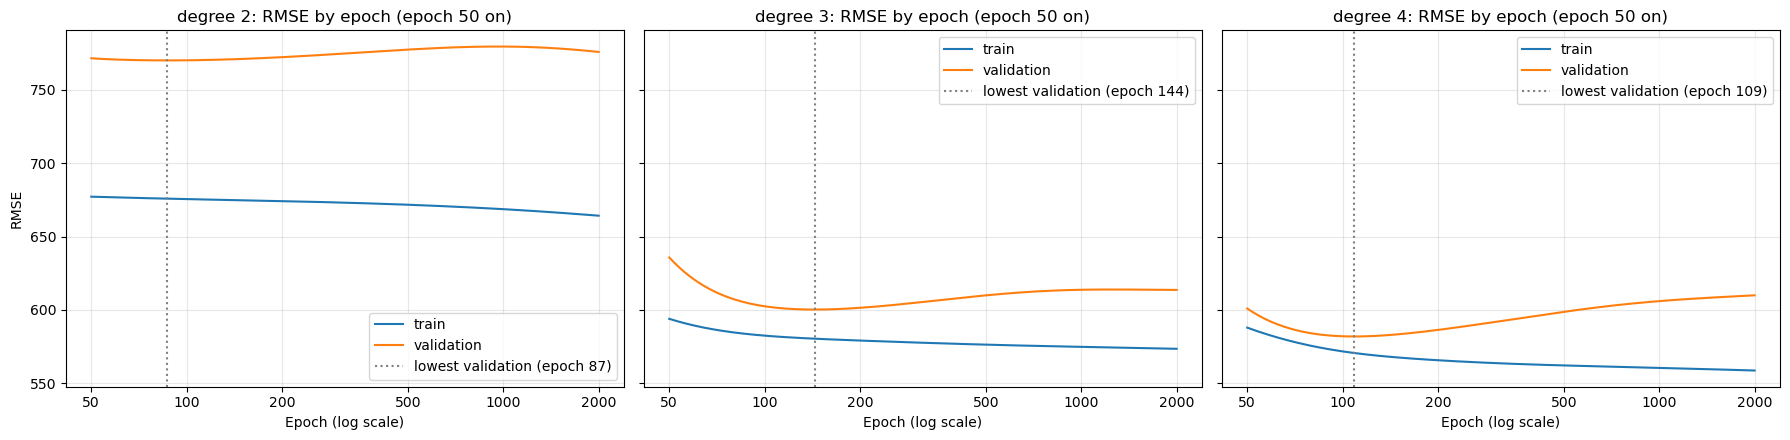

In [38]:
CURVE_FIRST_EPOCH = 50

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

# the first epochs are left out: RMSE starts in the thousands and would flatten everything after it.
# the x axis is a log scale, so the early epochs and the long tail can both be read
for ax, (name, scores) in zip(axes, curve_scores.items()):
	best_epoch = scores["val RMSE"].idxmin()
	scores = scores.loc[CURVE_FIRST_EPOCH:]
	ax.plot(scores.index, scores["train RMSE"], color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], color="C1", label="validation")
	ax.axvline(best_epoch, color="gray", linestyle=":", label=f"lowest validation (epoch {best_epoch})")
	ax.set_xscale("log")
	ax.set_xticks([50, 100, 200, 500, 1000, 2000])
	ax.set_xticklabels([50, 100, 200, 500, 1000, 2000])
	ax.minorticks_off()
	ax.set_xlabel("Epoch (log scale)")
	ax.set_title(f"{name}: RMSE by epoch (epoch {CURVE_FIRST_EPOCH} on)")
	ax.grid(alpha=0.3)
	ax.legend()
axes[0].set_ylabel("RMSE")

plt.tight_layout()
plt.show()

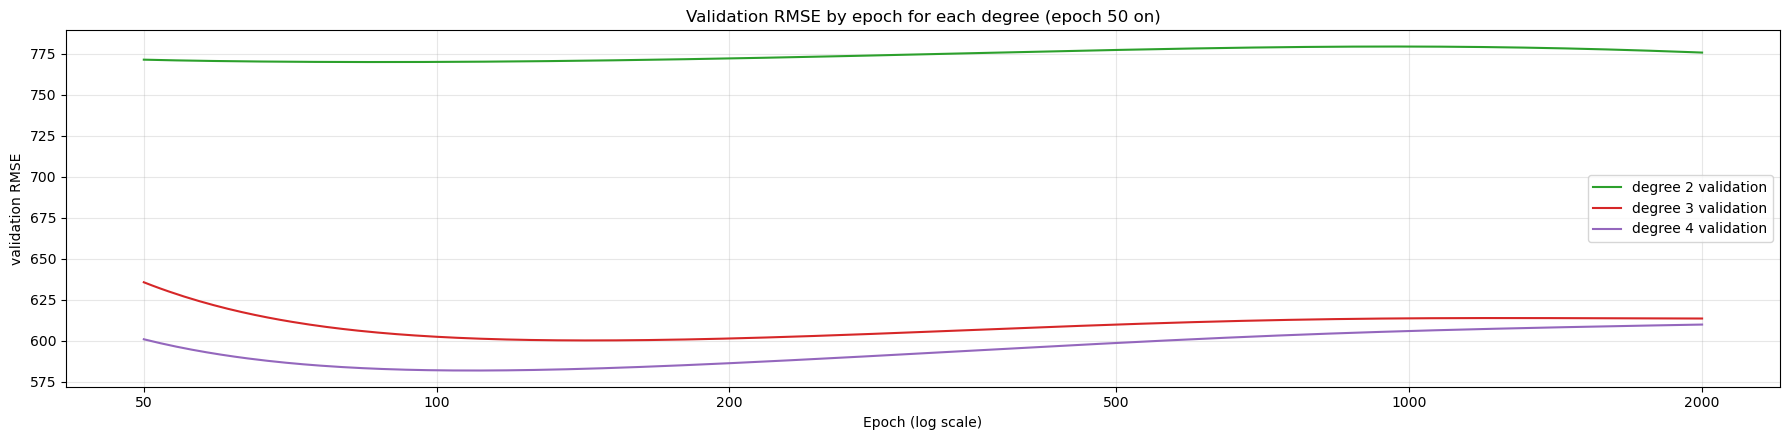

In [39]:
fig, ax = plt.subplots(figsize=(18, 4.5))

# the three validation lines on one chart
for (name, scores), color in zip(curve_scores.items(), ["C2", "C3", "C4"]):
	scores = scores.loc[CURVE_FIRST_EPOCH:]
	ax.plot(scores.index, scores["val RMSE"], color=color, label=f"{name} validation")
ax.set_xscale("log")
ax.set_xticks([50, 100, 200, 500, 1000, 2000])
ax.set_xticklabels([50, 100, 200, 500, 1000, 2000])
ax.minorticks_off()
ax.set_xlabel("Epoch (log scale)")
ax.set_ylabel("validation RMSE")
ax.set_title(f"Validation RMSE by epoch for each degree (epoch {CURVE_FIRST_EPOCH} on)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

**Loss by epoch and degree.** All three curves start at about the same level (a training RMSE of about 3665 to 3711 at epoch 1) and use the same rows, learning rate and seed, so the differences below come from the degree.

- **Degree 2 underfits.** Both lines flatten early and stay the highest: training RMSE is 675.4971 and validation RMSE 770.0733 at epoch 100, and 664.1925 and 775.7740 at epoch 2000. Its lowest validation RMSE (770.0042 at epoch 87) is far above what degrees 3 and 4 reach.
- **Degree 3 fits best for its size, and overfits slightly if it trains long.** Its validation RMSE is lowest at epoch 144 (600.2378). From there it rises slowly to 613.6055 at epoch 2000, while training RMSE falls from 582.4591 at epoch 100 to 573.4972.
- **Degree 4 overfits the most over time.** It reaches the lowest validation RMSE of the three (581.8942 at epoch 109) and the lowest training RMSE (558.6915 at epoch 2000). Its validation RMSE then rises the most: 586.3580 at epoch 200, 598.6993 at epoch 500 and 609.9224 at epoch 2000.

On this one fold degree 4 stays below degree 3 at every listed epoch from 20 on (ex 609.9224 against 613.6055 at epoch 2000). That differs from the six-fold comparison, where degree 4 is no better than degree 3. This curve covers one block of 31 days, and the degree was selected on all six.

## Summary

**Does the model overfit or underfit?** It depends on the degree, the penalty and how long SGD trains. Validation loss shows the same two patterns in each view. When the model underfits, training and validation RMSE are both high. When it overfits, training RMSE keeps improving while validation RMSE gets worse.

- **By degree** (closed form, 6 folds). Degrees 1 and 2 underfit: training and validation RMSE are both higher than at degree 3 (716.3116 and 1071.3037 at degree 1, 597.5274 and 872.6992 at degree 2, against 527.2374 and 747.5430). Degree 4 shows the first sign of overfitting: training RMSE falls to 498.4373 while validation RMSE rises to 771.5520, a rise that is within noise. The all-11 run is the extreme case: the lowest training RMSE and a failed validation fold.
- **By penalty** (SGD, degree 3). A strong L2 penalty underfits: Ridge at alpha 0.1 has a training RMSE of 578.6947 and a validation RMSE of 900.0014, against 544.9945 and 757.5680 for plain SGD. No penalty lowers validation RMSE by more than the noise, so the model is not overfitting in a way a penalty can fix.
- **By learning rate.** eta0 0.0001 underfits within the iteration limit (722.3646 and 1254.2938), and eta0 0.1 diverges.
- **By epoch** (last fold). Degree 2 underfits at every epoch. Degree 3 overfits mildly when it trains long: validation RMSE rises from 600.2378 at epoch 144 to 613.6055 at epoch 2000 while training RMSE keeps falling. Degree 4 does the same, more strongly.

The selected model (degree 3, Lasso, alpha 0.001, eta0 0.001) sits at the turning point: one degree lower underfits, and one degree higher starts to overfit without a gain. What remains is the gap between its training RMSE (544.4149) and its validation RMSE (752.9443) across the folds. That gap is there at every degree and every setting, including degree 1, so it comes from the later days differing from the earlier ones, not from a choice of degree, penalty or epochs.

# Reproducibility
No step depends on an unseeded random draw. The folds are time-ordered, so they involve no shuffle, and every `SGDRegressor` uses `random_state=42`. Running the notebook again from the top gives the same numbers.